# Taller 2 - Ciencia de Datos Aplicada
## Punto 1: Entendimiento y preparación de los datos

El análisis diferencia datos crudos de datos limpios. La preparación se hace de modo que el entrenamiento posterior pueda validarse sin fuga de información.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

RANDOM_STATE = 42
df_raw = pd.read_csv(Path("churn.csv"))
print("Dimensiones originales:", df_raw.shape)
display(df_raw.head())

Dimensiones originales: (10045, 11)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


### 1.0. Diccionario de datos y estructura

| Variable | Tipo conceptual | Interpretación |
|---|---|---|
| `credit_score` | Numérica | Puntaje de crédito del cliente |
| `country` | Categórica nominal | País: Francia, Alemania o España (con variaciones de escritura) |
| `gender` | Categórica nominal | Género consignado en el dataset |
| `age` | Numérica | Edad en años |
| `tenure` | Numérica discreta | Antigüedad de la relación con el banco (años) |
| `balance` | Numérica | Saldo de la cuenta |
| `products_number` | Discreta | Cantidad de productos bancarios |
| `credit_card` | Binaria | Indica tenencia de tarjeta de crédito |
| `active_member` | Binaria | Indica si el cliente es activo |
| `estimated_salary` | Numérica | Salario estimado |
| `churn` | Binaria / objetivo | 1: abandono; 0: no abandono |

No hay una columna de identificador en el CSV suministrado. Por eso, los duplicados exactos se revisan sobre todos los atributos disponibles. No es posible verificar la unicidad de personas distintas mediante un ID.

In [2]:
resumen_columnas = pd.DataFrame({
    "dtype_python": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "porcentaje_nulos": (df_raw.isna().mean() * 100).round(2),
    "valores_distintos": df_raw.nunique(dropna=True),
})
display(resumen_columnas)
print("Duplicados exactos:", int(df_raw.duplicated().sum()))
print("Filas con algún nulo:", int(df_raw.isna().any(axis=1).sum()))
print("Total de celdas nulas:", int(df_raw.isna().sum().sum()))
display(df_raw.describe().T.round(2))

,dtype_python,nulos,porcentaje_nulos,valores_distintos
credit_score,float64,250,2.49,461
country,object,0,0.00,9
gender,object,0,0.00,4
age,float64,300,2.99,76
tenure,int64,0,0.00,14
balance,float64,200,1.99,6240
products_number,int64,0,0.00,4
credit_card,int64,0,0.00,2
active_member,int64,0,0.00,2
estimated_salary,float64,350,3.48,9649


Duplicados exactos: 45
Filas con algún nulo: 1100
Total de celdas nulas: 1100


,count,mean,std,min,25%,50%,75%,max
credit_score,9795.0,650.69,97.09,95.0,584.00,652.00,718.00,1200.00
age,9745.0,38.94,10.73,-1.0,32.00,37.00,44.00,210.00
tenure,10045.0,5.02,2.90,-2.0,3.00,5.00,8.00,25.00
balance,9845.0,76317.50,62422.43,0.0,0.00,97042.60,127559.97,250898.09
products_number,10045.0,1.53,0.58,1.0,1.00,1.00,2.00,4.00
credit_card,10045.0,0.70,0.46,0.0,0.00,1.00,1.00,1.00
active_member,10045.0,0.51,0.50,0.0,0.00,1.00,1.00,1.00
estimated_salary,9695.0,100069.01,57510.69,-5000.0,51013.66,100130.95,149382.88,199992.48
churn,10045.0,0.20,0.40,0.0,0.00,0.00,0.00,1.00


### 1.1. Calidad de los datos

Se revisan las cuatro dimensiones vistas en clase: unicidad, completitud, consistencia y validez.

#### 1.1.1 Unicidad

In [3]:
n_dup = df_raw.duplicated().sum()
print(f'Filas duplicadas exactas: {n_dup} ({n_dup / len(df_raw):.2%})')
df_raw[df_raw.duplicated(keep=False)].sort_values(list(df_raw.columns)).head(6)

Filas duplicadas exactas: 45 (0.45%)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
5428,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
5672,497.0,France,Female,29.0,4,85646.81,1,0,0,63233.02,1
2390,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
7450,499.0,Germany,Male,36.0,5,131142.53,2,1,0,174918.46,0
2784,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0
6920,528.0,France,Female,27.0,7,176227.07,2,0,1,139481.53,0


#### 1.1.2 Completitud

In [4]:
nulos = pd.DataFrame({'nulos': df_raw.isna().sum(), '% del total': df_raw.isna().mean() * 100})
display(nulos[nulos['nulos'] > 0])
nulos_por_fila = df_raw.isna().sum(axis=1)
print(f'Filas con al menos un nulo: {(nulos_por_fila > 0).sum():,} ({(nulos_por_fila > 0).mean():.2%})')
print('Filas según cantidad de nulos:', nulos_por_fila.value_counts().sort_index().to_dict())

,nulos,% del total
credit_score,250,2.488800
age,300,2.986560
balance,200,1.991040
estimated_salary,350,3.484321


Filas con al menos un nulo: 1,100 (10.95%)
Filas según cantidad de nulos: {0: 8945, 1: 1100}


Cuatro columnas tienen nulos, todas por debajo del 5 %: `credit_score`, `age`, `balance` y `estimated_salary`.

#### 1.1.3 Consistencia

In [5]:
for col in ['country', 'gender']:
    print(f'--- {col}')
    print(df_raw[col].map(repr).value_counts().to_string(), '\n')

--- country
country
'France'      5003
'Germany'     2502
'Spain'       2475
'FRANCE'        22
'france '       17
'GERMANY'        9
'SPAIN'          9
'germany '       6
'spain '         2 

--- gender
gender
'Male'      5464
'Female'    4551
'M'           16
'F'           14 



- `country`: además de `France`, `Germany` y `Spain` aparecen variantes en mayúsculas (`FRANCE`) y en minúsculas con un espacio al final (`'france '`). Son 65 registros.
- `gender`: además de `Female` y `Male` aparecen las abreviaturas `F` y `M` (30 registros).

Si no se corrigen, el *one-hot encoding* crearía columnas distintas para el mismo país o género.

#### 1.1.4 Validez

In [6]:
rangos = {'credit_score': (300, 850), 'age': (18, 100), 'tenure': (0, 10),
          'balance': (0, None), 'products_number': (1, 4), 'estimated_salary': (0, None)}

def fuera_de_rango(df):
    filas = []
    for col, (lo, hi) in rangos.items():
        s = df[col]
        bajo = s < lo
        alto = s > hi if hi is not None else pd.Series(False, index=s.index)
        filas.append({'variable': col, 'rango válido': f'{lo} a {hi if hi is not None else "∞"}',
                      'bajo el mínimo': int(bajo.sum()), 'sobre el máximo': int(alto.sum()),
                      'valores inválidos': sorted(s[bajo | alto].tolist())})
    return pd.DataFrame(filas).set_index('variable')

for col in ['credit_card', 'active_member', 'churn']:
    assert set(df_raw[col].unique()) <= {0, 1}, col
fuera_de_rango(df_raw)

,rango válido,bajo el mínimo,sobre el máximo,valores inválidos
variable,,,,
credit_score,300 a 850,2,2,"[95.0, 120.0, 999.0, 1200.0]"
age,18 a 100,3,3,"[-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]"
tenure,0 a 10,1,2,"[-2, 15, 25]"
balance,0 a ∞,0,0,[]
products_number,1 a 4,0,0,[]
estimated_salary,0 a ∞,3,0,"[-5000.0, -120.5, -1.0]"


Hay 16 valores fuera de rango en cuatro variables. Las binarias, `balance` y `products_number` están dentro de su rango. Los valores inválidos no son extremos sino imposibles: edades de 0, −1, 5, 130, 150 y 210 años; un `credit_score` de 999 o de 95; antigüedades de −2 y 25 años; salarios negativos.

#### 1.1.5 Resumen de calidad

In [7]:
resumen_calidad = pd.DataFrame([
    ('Unicidad',     'Filas duplicadas exactas',                     n_dup),
    ('Completitud',  'Celdas nulas (4 columnas)',                    int(df_raw.isna().sum().sum())),
    ('Consistencia', 'Registros con country mal escrito',            int((~df_raw['country'].isin(['France', 'Germany', 'Spain'])).sum())),
    ('Consistencia', 'Registros con gender abreviado',               int((~df_raw['gender'].isin(['Female', 'Male'])).sum())),
    ('Validez',      'Valores fuera del rango del diccionario',      int(fuera_de_rango(df_raw)[['bajo el mínimo', 'sobre el máximo']].sum().sum())),
], columns=['dimensión', 'problema', 'casos']).set_index('dimensión')
resumen_calidad['% de registros'] = resumen_calidad['casos'] / len(df_raw) * 100
resumen_calidad

,problema,casos,% de registros
dimensión,,,
Unicidad,Filas duplicadas exactas,45,0.447984
Completitud,Celdas nulas (4 columnas),1100,10.950722
Consistencia,Registros con country mal escrito,65,0.647088
Consistencia,Registros con gender abreviado,30,0.298656
Validez,Valores fuera del rango del diccionario,16,0.159283


### 1.2. Auditoría de calidad

Hallazgos sobre el CSV original: existen 45 filas idénticas; hay valores faltantes en `credit_score`, `age`, `balance` y `estimated_salary`. `country` aparece con diferentes mayúsculas y `gender` mezcla nombres completos con abreviaturas. También hay valores numéricos improbables.

**Procedimiento de limpieza a ejecutar:**

1. Estandarizar países y géneros (por ejemplo, `FRANCE` -> `France`, `F` -> `Female`).
2. Eliminar filas duplicadas exactas. No se eliminarán clientes solo porque compartan una o dos características.
3. Convertir a faltante (`NaN`) los valores numéricos imposibles o fuera de los rangos adoptados: edad fuera de 18–100, antigüedad fuera de 0–10, puntaje crediticio fuera de 300–850 y salario negativo. Los rangos para antigüedad y puntaje son supuestos sobre este dataset, no reglas universales de todas las entidades financieras.
4. No eliminar las filas que contienen valores faltantes: se imputarán más adelante, aprendiendo las estadísticas exclusivamente del conjunto de entrenamiento.

In [8]:
# Crear una copia. El archivo original se conserva intacto.
df = df_raw.copy()
df["country"] = df["country"].astype("string").str.strip().str.title()
df["gender"] = df["gender"].astype("string").str.strip().replace({"F": "Female", "M": "Male"})

filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
duplicados_eliminados = filas_antes - len(df)

# Los valores fuera del dominio adoptado pasan a NaN: la imputación irá en el pipeline.
limites = {"credit_score": (300, 850), "age": (18, 100), "tenure": (0, 10)}
corregidos = {}
for col, (minimo, maximo) in limites.items():
    mask = df[col].notna() & ~df[col].between(minimo, maximo)
    corregidos[col] = int(mask.sum())
    df.loc[mask, col] = np.nan
mask_salario = df["estimated_salary"].lt(0)
corregidos["estimated_salary"] = int(mask_salario.sum())
df.loc[mask_salario, "estimated_salary"] = np.nan

print(f"Registros antes: {filas_antes:,} | duplicados eliminados: {duplicados_eliminados} | después: {len(df):,}")
print("Anomalías numéricas convertidas a NaN:", corregidos)
print("Nulos después de la limpieza:")
display(pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": (100*df.isna().mean()).round(2)}))

Registros antes: 10,045 | duplicados eliminados: 45 | después: 10,000
Anomalías numéricas convertidas a NaN: {'credit_score': 4, 'age': 6, 'tenure': 3, 'estimated_salary': 3}
Nulos después de la limpieza:


,nulos,porcentaje
credit_score,254,2.54
country,0,0.00
gender,0,0.00
age,306,3.06
tenure,3,0.03
balance,200,2.00
products_number,0,0.00
credit_card,0,0.00
active_member,0,0.00
estimated_salary,353,3.53


### 1.3. Distribución de la variable objetivo

La tasa de abandono se calcula como la proporción de registros en que churn = 1. Conviene reportar la proporción antes y después de la depuración para verificar que la limpieza no ha alterado sustancialmente la composición de las clases.

,Conjunto,Clientes,Abandonan,Tasa de abandono (%)
0,Original,10045,2045,20.36
1,Depurado,10000,2037,20.37


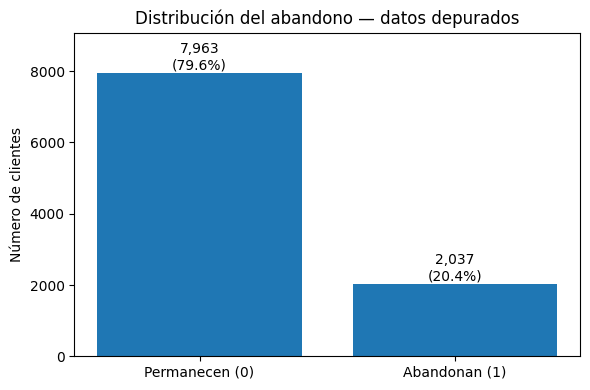

In [9]:
comparacion = pd.DataFrame({
    "Conjunto": ["Original", "Depurado"],
    "Clientes": [len(df_raw), len(df)],
    "Abandonan": [int(df_raw.churn.sum()), int(df.churn.sum())],
    "Tasa de abandono (%)": [round(100*df_raw.churn.mean(), 2), round(100*df.churn.mean(), 2)],
})
display(comparacion)

conteos = df["churn"].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Permanecen (0)", "Abandonan (1)"], conteos.values)
for barra, valor in zip(bars, conteos.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 90, f"{valor:,}\n({100*valor/len(df):.1f}%)", ha="center")
ax.set_ylim(0, max(conteos.values)*1.14)
ax.set_ylabel("Número de clientes")
ax.set_title("Distribución del abandono — datos depurados")
plt.tight_layout(); plt.show()

### 1.4. Distribuciones numéricas

Los histogramas permiten revisar la dispersión de las variables numéricas y posibles acumulaciones. La comparación entre churn = 0 y churn = 1 puede sugerir asociaciones útiles, pero no puede demostrar causalidad.

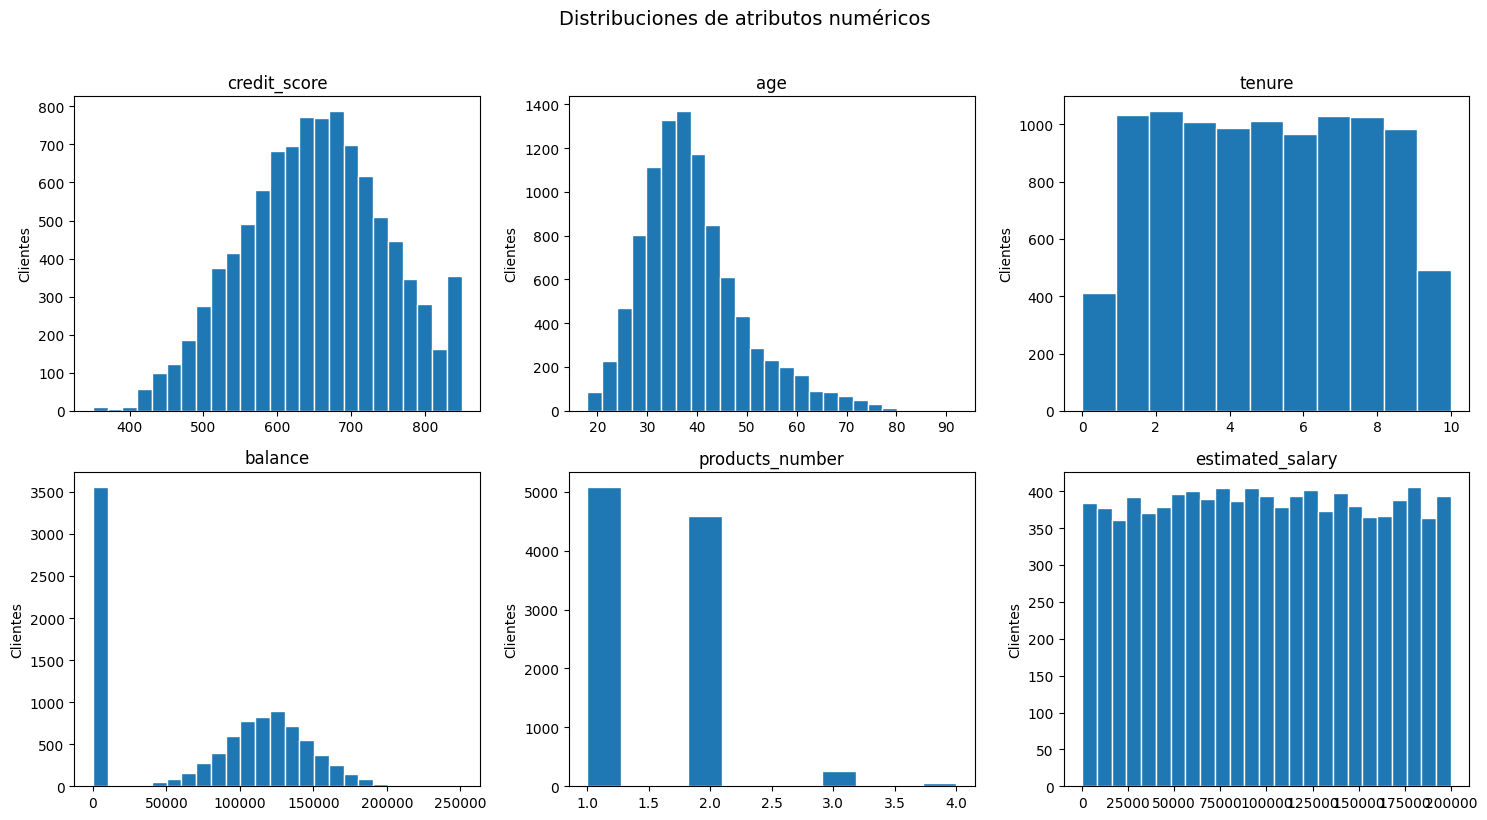

Medianas por estado de abandono:


,age,credit_score,tenure,balance,estimated_salary
churn,,,,,
0,36.0,654.0,5.0,91835.16,99654.13
1,45.0,646.0,5.0,109153.96,102127.30


In [10]:
columnas_num = ["credit_score", "age", "tenure", "balance", "products_number", "estimated_salary"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, columnas_num):
    ax.hist(df[col].dropna(), bins=25 if col not in ["tenure", "products_number"] else 11, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Clientes")
plt.suptitle("Distribuciones de atributos numéricos", y=1.02, fontsize=14)
plt.tight_layout();plt.show()

print("Medianas por estado de abandono:")
display(df.groupby("churn")[["age", "credit_score", "tenure", "balance", "estimated_salary"]].median().round(2))

### 1.5. Variables categóricas y relación con el abandono

Para cada grupo, se muestran simultáneamente la tasa de churn y su tamaño. Interpretar una tasa extrema sin conocer cuántos clientes la componen puede llevar a conclusiones engañosas; además, diferencias observadas entre grupos no implican que la categoría sea la causa del abandono.

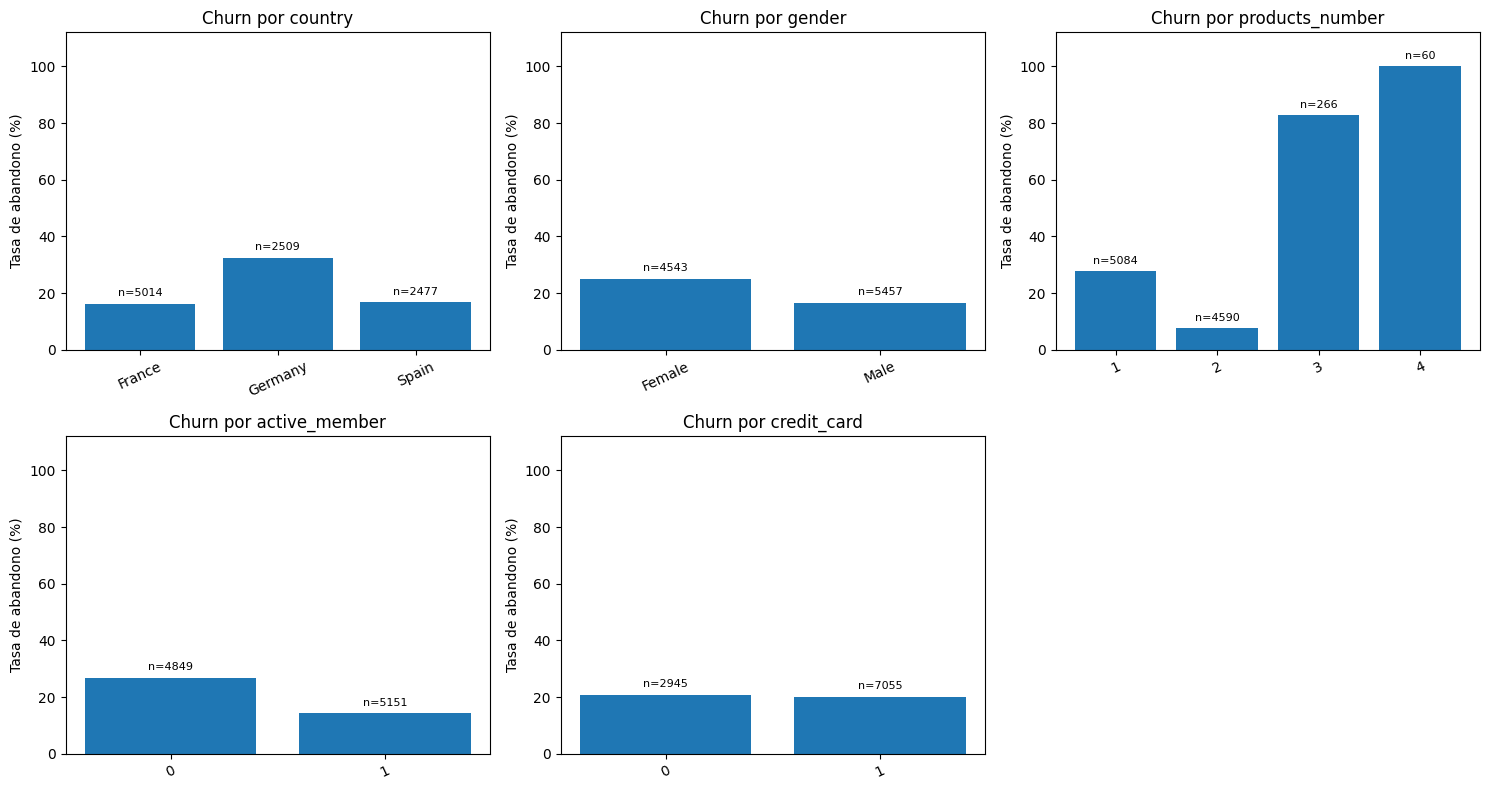

Tasa por country


,clientes,abandonan,churn (%)
country,,,
France,5014,810,16.15
Germany,2509,814,32.44
Spain,2477,413,16.67


Tasa por gender


,clientes,abandonan,churn (%)
gender,,,
Female,4543,1139,25.07
Male,5457,898,16.46


Tasa por products_number


,clientes,abandonan,churn (%)
products_number,,,
1,5084,1409,27.71
2,4590,348,7.58
3,266,220,82.71
4,60,60,100.00


Tasa por active_member


,clientes,abandonan,churn (%)
active_member,,,
0,4849,1302,26.85
1,5151,735,14.27


Tasa por credit_card


,clientes,abandonan,churn (%)
credit_card,,,
0,2945,613,20.81
1,7055,1424,20.18


In [11]:
columnas_grupo = ["country", "gender", "products_number", "active_member", "credit_card"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, columnas_grupo):
    resumen = df.groupby(col, dropna=False)["churn"].agg(n="size", tasa="mean").sort_index()
    bars = ax.bar(resumen.index.astype(str), resumen["tasa"]*100)
    ax.set_title(f"Churn por {col}")
    ax.set_ylabel("Tasa de abandono (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, 112)
    for barra, n in zip(bars, resumen["n"]):
        ax.text(barra.get_x()+barra.get_width()/2, barra.get_height()+2,
                f"n={n}", ha="center", va="bottom", fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout();plt.show()

for col in columnas_grupo:
    print(f"Tasa por {col}")
    tabla = df.groupby(col)["churn"].agg(clientes="size", abandonan="sum", tasa="mean")
    tabla["tasa"] = (100*tabla["tasa"]).round(2)
    display(tabla.rename(columns={"tasa": "churn (%)"}))

### 1.6. Conclusiones descriptivas

Los resultados permiten formular hipótesis descriptivas para la etapa de modelado:

- La clase de abandono es minoritaria (aproximadamente una quinta parte de los clientes), por lo que no debemos seleccionar un modelo exclusivamente por accuracy.
- `age`, `products_number`, `active_member` y `country` presentan diferencias visibles entre grupos, conviene contrastarlas con modelos e interpretabilidad.
- La tasa para clientes con cuatro productos es especialmente alta, pero se basa en un grupo pequeño, por lo que no se debe generalizar sin evaluar incertidumbre.
- El conjunto es europeo. Para aplicar el modelo a Colombia habrá posibles cambios en mercado, clientes y distribución de atributos.
- Las diferencias entre categorías de género u otras características deben tratarse con cuidado y sin interpretarlas como relaciones causales.

### 1.7. División estratificada

Para facilitar una comparación justa de al menos dos modelos, se conservará la misma división estratificada 60 % entrenamiento, 20 % validación y 20 % prueba, con semilla 42, como en las prácticas de clasificación.

**Prevención de fuga de información:** la imputación de numéricas con mediana, el escalamiento `StandardScaler` y la codificación one-hot se definen dentro de un `ColumnTransformer`. Cuando optimicemos hiperparámetros con validación cruzada, ese transformador debe estar dentro del `Pipeline` del modelo, de manera que se ajuste en cada fold solo con sus datos de entrenamiento. La prueba final quedará reservada para la evaluación definitiva.

No balanceamos clases todavía: hacerlo indiscriminadamente alteraría la prevalencia relevante para el negocio. Si en el punto 2 se compara ponderación de clases o remuestreo, deberá aplicarse únicamente en entrenamiento, idealmente dentro de validación cruzada.

In [12]:
# Partición de índices con estratificación para conservar la prevalencia de churn.
X = df.drop(columns=["churn"]).copy()
y = df["churn"].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

tabla_particiones = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Filas": [len(X_train), len(X_val), len(X_test)],
    "Churn (%)": [round(100*s.mean(), 2) for s in [y_train, y_val, y_test]],
})
display(tabla_particiones)

numericas = ["credit_score", "age", "tenure", "balance", "products_number", "estimated_salary"]
binarias = ["credit_card", "active_member"]
categoricas = ["country", "gender"]

preprocessor = ColumnTransformer(transformers=[
    ("numericas", Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
    ]), numericas),
    ("binarias", "passthrough", binarias),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
], remainder="drop")

# Solo comprobación de que la transformación funciona; se reajustará dentro del Pipeline del modelo durante la validación cruzada.
preprocessor_demo = clone(preprocessor)
X_train_demo = preprocessor_demo.fit_transform(X_train)
X_val_demo = preprocessor_demo.transform(X_val)
X_test_demo = preprocessor_demo.transform(X_test)
for nombre, X_t in [("Train", X_train_demo), ("Val", X_val_demo), ("Test", X_test_demo)]:
    X_arr = X_t.toarray() if hasattr(X_t, "toarray") else np.asarray(X_t)
    print(f"{nombre}: {X_arr.shape} | nulos: {np.isnan(X_arr).sum()} | infinitos: {np.isinf(X_arr).sum()}")

,Conjunto,Filas,Churn (%)
0,Entrenamiento,6000,20.37
1,Validación,2000,20.40
2,Prueba,2000,20.35


Train: (6000, 13) | nulos: 0 | infinitos: 0
Val: (2000, 13) | nulos: 0 | infinitos: 0
Test: (2000, 13) | nulos: 0 | infinitos: 0


In [13]:
imputador = (
    preprocessor_demo
    .named_transformers_["numericas"]
    .named_steps["imputacion"]
)

tabla_imputacion = pd.DataFrame({
    "Variable": numericas,
    "Mediana de entrenamiento": imputador.statistics_,
    "Nulos en entrenamiento": X_train[numericas].isna().sum().values
})

display(tabla_imputacion)

,Variable,Mediana de entrenamiento,Nulos en entrenamiento
0,credit_score,652.00,150
1,age,37.00,193
2,tenure,5.00,3
3,balance,96694.39,132
4,products_number,1.00,0
5,estimated_salary,100930.38,208


### 1.8. Cierre del punto 1

**Se documentó:** tamaño y estructura, diccionario de variables, faltantes, duplicados e inconsistencias, distribuciones, tasas de abandono por subgrupos, conjunto depurado y particiones sin solapamiento, transformador reutilizable para el entrenamiento.

**Decisiones a evaluar en el siguiente punto:** comparar por lo menos dos clasificadores, seleccionar por resultados en validación sin consultar prueba, usar métricas apropiadas para la clase positiva e investigar si las características derivadas de la Práctica 2 mejoran el F1 o el beneficio esperado.

**Límites:** no hay identificador único que confirme personas distintas; no conocemos fechas de observación ni la definición operacional exacta de abandono. El origen europeo limita la extrapolación a Colombia.

# Punto 2: Entrenamiento del modelo de Machine Learning

**Objetivo del enunciado:** entrenar al menos dos modelos para predecir `churn`, documentar las divisiones, la estimación de hiperparámetros y la selección del modelo.

**Metodología:**

1. Comparar una regresión logística, un árbol de decisión y un Random Forest, como en la Práctica 2 (Clasificación).
2. Ajustar los hiperparámetros con `GridSearchCV` y validación cruzada estratificada de cinco particiones solo sobre entrenamiento.
3. Mantener `preprocessor` dentro de cada pipeline para que la imputación, la codificación y el escalamiento se ajusten correctamente en cada partición de la validación cruzada.
4. Usar validación (20 %) para comparar los algoritmos y seleccionar el mejor. No consultar el conjunto de prueba (20 %) en este punto.

**Métrica prioritaria:** F1 para `churn = 1`. El abandono es la clase minoritaria y, para el negocio, importan tanto los falsos negativos (clientes en riesgo que no son detectados) como los falsos positivos (clientes contactados innecesariamente). Revisaremos también `precision` y `recall`, pero la decisión económica definitiva se realizará en el punto 5.

### 2.1. Definición de modelos y espacio de hiperparámetros

Los tres clasificadores usan exactamente las mismas variables de entrada, particiones y pasos de preprocesamiento del punto 1.

- **Regresión logística:** como modelo de referencia lineal; se busca la intensidad de regularización `C` y si se compensa el desbalance por ponderación de clases.
- **Árbol de decisión:** permite reglas interpretables; se busca la profundidad máxima, el mínimo de observaciones por hoja y la ponderación de clases para controlar el sobreajuste.
- **Random Forest:** ensamble de árboles que puede capturar interacciones y relaciones no lineales; se busca profundidad, tamaño mínimo de las hojas y ponderación de clases. Se usan 200 árboles en todos los candidatos para mantener comparabilidad y moderar el costo computacional.

`class_weight="balanced"` no remuestrea ni modifica la proporción real de abandono: asigna mayor peso a la clase minoritaria durante el entrenamiento.

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

configuraciones = {
    "Regresión logística": {
        "estimador": LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE),
        "parametros": {
            "clasificador__C": [0.1, 1.0, 10.0],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
    "Árbol de decisión": {
        "estimador": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "parametros": {
            "clasificador__max_depth": [4, 7, 10],
            "clasificador__min_samples_leaf": [10, 30],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
    "Random Forest": {
        "estimador": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
        "parametros": {
            "clasificador__max_depth": [8, None],
            "clasificador__min_samples_leaf": [2, 10],
            "clasificador__class_weight": [None, "balanced"],
        },
    },
}

espacio_busqueda = pd.DataFrame([
    {"Modelo": nombre,
     "Configuraciones": int(np.prod([len(v) for v in config["parametros"].values()])),
     "Parámetros": ", ".join(p.replace("clasificador__", "") for p in config["parametros"])}
    for nombre, config in configuraciones.items()
])
display(espacio_busqueda)

,Modelo,Configuraciones,Parámetros
0,Regresión logística,6,"C, class_weight"
1,Árbol de decisión,12,"max_depth, min_samples_leaf, class_weight"
2,Random Forest,8,"max_depth, min_samples_leaf, class_weight"


### 2.2. Búsqueda de hiperparámetros con validación cruzada

Para cada modelo, `GridSearchCV` entrena todos los candidatos en cinco particiones estratificadas del conjunto de entrenamiento (6.000 clientes). Su criterio de selección es el promedio de F1 para la clase de abandono. El mejor modelo se reajusta automáticamente utilizando los 6.000 registros de entrenamiento (`refit=True`).

Como `preprocessor` está dentro del `Pipeline`, las medianas y los parámetros de escalamiento de cada iteración se calculan únicamente con la parte de entrenamiento correspondiente. Así evitamos fuga de información durante la búsqueda.

In [15]:
busquedas = {}
mejores_modelos = {}
filas_cv = []

for nombre, config in configuraciones.items():
    pipeline = Pipeline([
        ("preprocesamiento", clone(preprocessor)),
        ("clasificador", clone(config["estimador"])),
    ])

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=config["parametros"],
        scoring="f1",
        cv=cv,
        refit=True,
        n_jobs=2,
        return_train_score=False,
        error_score="raise",
    )
    busqueda.fit(X_train, y_train)

    busquedas[nombre] = busqueda
    mejores_modelos[nombre] = busqueda.best_estimator_
    idx = busqueda.best_index_
    filas_cv.append({
        "Modelo": nombre,
        "F1_CV_promedio": busqueda.best_score_,
        "F1_CV_desviacion": busqueda.cv_results_["std_test_score"][idx],
        "Mejores_hiperparametros": {k.replace("clasificador__", ""): v
                                    for k, v in busqueda.best_params_.items()},
    })
    print(f"{nombre}: mejor F1 CV = {busqueda.best_score_:.4f} | "
          f"parámetros = {filas_cv[-1]['Mejores_hiperparametros']}")

tabla_cv = pd.DataFrame(filas_cv).sort_values("F1_CV_promedio", ascending=False).reset_index(drop=True)
display(tabla_cv)

Regresión logística: mejor F1 CV = 0.4954 | parámetros = {'C': 1.0, 'class_weight': 'balanced'}
Árbol de decisión: mejor F1 CV = 0.5691 | parámetros = {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 10}
Random Forest: mejor F1 CV = 0.6108 | parámetros = {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2}


,Modelo,F1_CV_promedio,F1_CV_desviacion,Mejores_hiperparametros
0,Random Forest,0.610811,0.033622,"{'class_weight': 'balanced', 'max_depth': None..."
1,Árbol de decisión,0.569116,0.020302,"{'class_weight': 'balanced', 'max_depth': 7, '..."
2,Regresión logística,0.495436,0.019084,"{'C': 1.0, 'class_weight': 'balanced'}"


### 2.3. Comparación sobre validación

Tras encontrar los mejores hiperparámetros de cada algoritmo, evaluamos sus predicciones sobre los 2.000 clientes de validación, que no participaron en las búsquedas.

Usamos el mismo umbral de 0,5 para que la comparación sea coherente. Para `churn = 1`, la precisión indica qué proporción de los clientes marcados como posibles desertores realmente abandonó. El recall indica qué proporción de los desertores reales fue detectada. F1 resume ambas métricas.

In [16]:
filas_validacion = []

for nombre, modelo in mejores_modelos.items():
    pred_val = modelo.predict(X_val)
    pred_train = modelo.predict(X_train)
    filas_validacion.append({
        "Modelo": nombre,
        "F1_validacion": f1_score(y_val, pred_val),
        "Precision_validacion": precision_score(y_val, pred_val, zero_division=0),
        "Recall_validacion": recall_score(y_val, pred_val, zero_division=0),
        "Exactitud_validacion": accuracy_score(y_val, pred_val),
        "F1_entrenamiento": f1_score(y_train, pred_train),
    })

tabla_validacion = (pd.DataFrame(filas_validacion)
                    .sort_values(["F1_validacion", "Recall_validacion"], ascending=False)
                    .reset_index(drop=True))
tabla_validacion["Brecha_train_val"] = (
    tabla_validacion["F1_entrenamiento"] - tabla_validacion["F1_validacion"]
)
display(tabla_validacion.round(4))

,Modelo,F1_validacion,Precision_validacion,Recall_validacion,Exactitud_validacion,F1_entrenamiento,Brecha_train_val
0,Random Forest,0.5961,0.5918,0.6005,0.834,0.9360,0.3399
1,Árbol de decisión,0.5639,0.4705,0.7034,0.778,0.6144,0.0506
2,Regresión logística,0.4895,0.3804,0.6863,0.708,0.4944,0.0049


### 2.4. Visualización y diagnóstico de sobreajuste

La comparación de F1 de validación cruzada y de validación independiente permite revisar si los resultados son consistentes. También calculamos la brecha entre F1 de entrenamiento y de validación: una brecha positiva muy grande puede indicar sobreajuste.

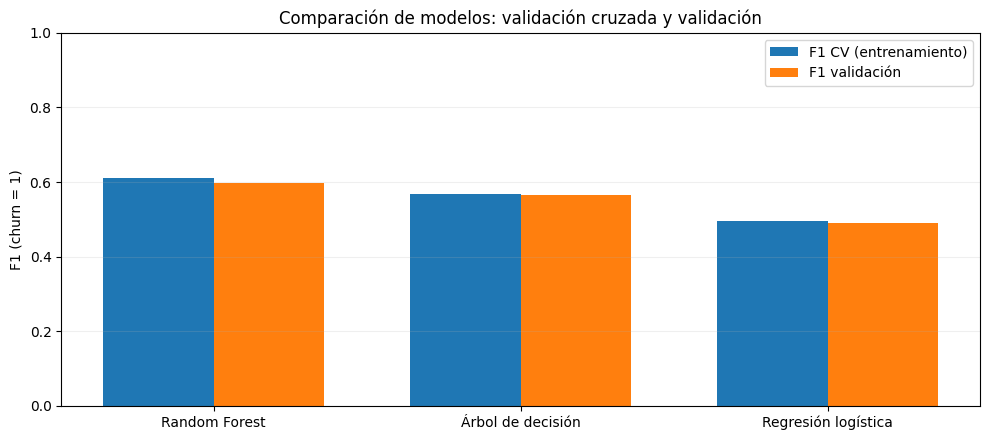

In [17]:
comparacion = tabla_validacion.merge(
    tabla_cv[["Modelo", "F1_CV_promedio"]], on="Modelo", how="left"
)

x_pos = np.arange(len(comparacion))
ancho = 0.36
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x_pos - ancho / 2, comparacion["F1_CV_promedio"], ancho, label="F1 CV (entrenamiento)")
ax.bar(x_pos + ancho / 2, comparacion["F1_validacion"], ancho, label="F1 validación")
ax.set_xticks(x_pos, comparacion["Modelo"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1 (churn = 1)")
ax.set_title("Comparación de modelos: validación cruzada y validación")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 2.5. Selección del modelo para los puntos siguientes

**Regla de selección:** el modelo con mayor F1 de validación, usando 0,5 como umbral.

In [18]:
nombre_modelo_final = tabla_validacion.loc[0, "Modelo"]
modelo_final = mejores_modelos[nombre_modelo_final]
hiperparametros_finales = tabla_cv.set_index("Modelo").loc[
    nombre_modelo_final, "Mejores_hiperparametros"
]

print("Modelo seleccionado:", nombre_modelo_final)
print("Hiperparámetros:", hiperparametros_finales)
print("F1 de validación:", round(float(tabla_validacion.loc[0, "F1_validacion"]), 4))
print("Recall de validación:", round(float(tabla_validacion.loc[0, "Recall_validacion"]), 4))

assert set(mejores_modelos) == set(configuraciones)
assert len(X_train) == 6000 and len(X_val) == 2000 and len(X_test) == 2000

Modelo seleccionado: Random Forest
Hiperparámetros: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2}
F1 de validación: 0.5961
Recall de validación: 0.6005


### 2.6. Resultados y conclusiones del entrenamiento

En validación, Random Forest fue el mejor modelo con F1 = 0,5961, seguido por árbol de decisión (F1 = 0,5639) y regresión logística (F1 = 0,4895). El resultado de Random Forest es consistente con su promedio de F1 en validación cruzada (0,6108), por lo que la diferencia entre ambos conjuntos es pequeña.

**Comparación desde el problema de negocio:** Random Forest presenta mejor precisión (0,5918) que el árbol de decisión (0,4705), mientras que el árbol presenta mejor recall (0,7034 frente a 0,6005). Esto revela un intercambio relevante: si la empresa prioriza detectar más posibles desertores, el árbol merece consideración, pero contactaría proporcionalmente a más clientes que no abandonan. La decisión económica se examinará con los costos y beneficios del punto 5.

**Hiperparámetros elegidos mediante validación cruzada:**

- Regresión logística: `C=1.0`, `class_weight="balanced"`.
- Árbol de decisión: `max_depth=7`, `min_samples_leaf=10`, `class_weight="balanced"`.
- Random Forest: `n_estimators=200`, `max_depth=None`, `min_samples_leaf=2`, `class_weight="balanced"`.

**Sobreajuste:** Random Forest obtuvo F1 = 0,9360 en entrenamiento y 0,5961 en validación; la brecha de 0,3399 es una señal importante de sobreajuste. Aunque el F1 de validación es cercano al promedio de la CV, el rendimiento sobre los datos de entrenamiento es considerablemente mayor y no representa el desempeño esperado en clientes nuevos. No se deben tratar las diferencias observadas como prueba de superioridad estadística: para eso se utilizarán las técnicas de comparación de la Práctica 4 en el punto 3.

**Selección actual:** `nombre_modelo_final = "Random Forest"` y `modelo_final` contiene el pipeline ya entrenado, incluyendo la preparación y el clasificador. La selección se realizó sin calcular predicciones ni métricas sobre el conjunto de prueba.

**Limitaciones:** los datos proceden de clientes europeos, no se conoce la ventana temporal exacta del abandono y el umbral usado todavía es 0,5. Antes de aplicar el modelo a un banco colombiano se necesitaría validar su desempeño local y ajustar las decisiones al impacto económico de la campaña.

# Punto 3: Análisis cuantitativo de los resultados

**Objetivo:** calcular las métricas de evaluación de los modelos, explicar qué representan en el problema de abandono y justificar la selección del punto 2. Se revisarán los errores, la capacidad de ordenar clientes por riesgo y la incertidumbre de las métricas.

**Metodología:**

- Se usan los tres pipelines ya entrenados en el punto 2. No se buscan hiperparámetros ni se reentrena usando prueba.
- Se evalúa una sola vez el conjunto de prueba estratificado con el umbral original de 0,5.
- La comparación estadística posterior es descriptiva y confirmatoria, no se usa para elegir un modelo nuevo ni para ajustar el umbral con prueba.
- `churn = 1` es la clase positiva. Una predicción positiva produciría un contacto en una campaña hipotética, esto no significa que el cliente acepte la oferta.

Referencia metodológica: Práctica 4 (bootstrapping y comparación de modelos) y las diapositivas de vistas en clase.

### 3.1. Métricas sobre el conjunto de prueba

- **Precisión (VP/(VP+FP))**: de los clientes que el modelo recomienda contactar, qué proporción realmente iba a abandonar. Una precisión alta permite evitar campañas innecesarias.
- **Recall (VP/(VP+FN))**: de los clientes que iban a abandonar, cuántos detectamos. Un valor alto reduce oportunidades de retención perdidas.
- **F1**: media armónica de precisión y recall. Es la métrica de selección utilizada en el punto 2.
- **Accuracy ((VP+VN)/N)**: proporción global de aciertos; se debe comparar con la referencia de predecir siempre la clase mayoritaria.
- **Especificidad (VN/(VN+FP))**: proporción de clientes que permanecen y son correctamente excluidos de la campaña.
- **ROC-AUC**: discriminación entre quienes abandonan y quienes no, sobre todos los umbrales.
- **AP (average precision)** resume precisión-recall con énfasis en la clase positiva.

In [19]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    balanced_accuracy_score,
)

# Mantener la selección del punto 2 sin recalibrar ni reentrenar modelos.
predicciones_test = {}
probabilidades_test = {}
matrices_test = {}
filas_test = []

for nombre, modelo in mejores_modelos.items():
    pred = np.asarray(modelo.predict(X_test))
    prob = np.asarray(modelo.predict_proba(X_test)[:, 1])
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    predicciones_test[nombre] = pred
    probabilidades_test[nombre] = prob
    matrices_test[nombre] = (tn, fp, fn, tp)

    filas_test.append({
        "Modelo": nombre,
        "F1": f1_score(y_test, pred, zero_division=0),
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Exactitud": accuracy_score(y_test, pred),
        "Especificidad": tn / (tn + fp),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "AP (PR)": average_precision_score(y_test, prob),
        "Contactados": int(tp + fp),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    })

tabla_test = (pd.DataFrame(filas_test)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True))

baseline_mayoritaria = float((y_test == 0).mean())
print(f"Clientes en prueba: {len(y_test):,} | churn: {y_test.mean():.2%}")
print(f"Exactitud de predecir siempre NO churn: {baseline_mayoritaria:.4f} (F1 para churn = 0)")
display(tabla_test.round(4))


Clientes en prueba: 2,000 | churn: 20.35%
Exactitud de predecir siempre NO churn: 0.7965 (F1 para churn = 0)


,Modelo,F1,Precisión,Recall,Exactitud,Especificidad,Balanced accuracy,ROC-AUC,AP (PR),Contactados,VP,FP,FN,VN
0,Random Forest,0.6258,0.6378,0.6143,0.8505,0.9109,0.7626,0.8587,0.6832,392,250,142,157,1451
1,Árbol de decisión,0.5556,0.4604,0.7002,0.7720,0.7903,0.7453,0.8339,0.6534,619,285,334,122,1259
2,Regresión logística,0.4926,0.3828,0.6904,0.7105,0.7156,0.7030,0.7630,0.4491,734,281,453,126,1140


### 3.2. Matrices de confusión y tipos de error

En cada matriz las filas son las clases reales y las columnas son las predicciones:

| | Predice permanencia (0) | Predice abandono (1) |
|---|---|---|
| Permanece (0) | Verdaderos negativos (VN) | Falsos positivos (FP): campaña innecesaria |
| Abandona (1) | Falsos negativos (FN): oportunidad perdida | Verdaderos positivos (VP): campaña focalizada |

La empresa debe prestar atención a FP y FN, ambos representan costos o beneficios potencialmente perdidos.

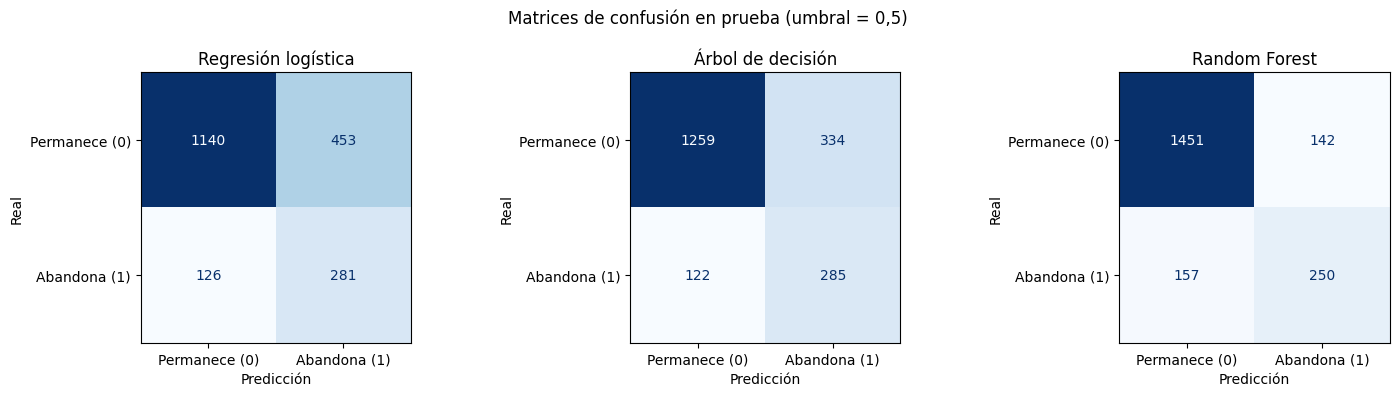

,Modelo,Contactados,VP,FP,FN,VN,Contactados (%)
0,Random Forest,392,250,142,157,1451,19.60
1,Árbol de decisión,619,285,334,122,1259,30.95
2,Regresión logística,734,281,453,126,1140,36.70


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, mejores_modelos):
    cm = confusion_matrix(y_test, predicciones_test[nombre], labels=[0, 1])
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Permanece (0)", "Abandona (1)"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.suptitle("Matrices de confusión en prueba (umbral = 0,5)")
plt.tight_layout()
plt.show()

resumen_contacto = tabla_test[["Modelo", "Contactados", "VP", "FP", "FN", "VN"]].copy()
resumen_contacto["Contactados (%)"] = (100 * resumen_contacto["Contactados"] / len(y_test)).round(2)
display(resumen_contacto)


### 3.3. Curvas ROC y precisión-recall

Las curvas permiten comparar los algoritmos sin imponer un único umbral. La línea diagonal en ROC representa discriminación aleatoria. En la gráfica precisión-recall, la línea horizontal de referencia corresponde a la prevalencia de abandono en prueba.

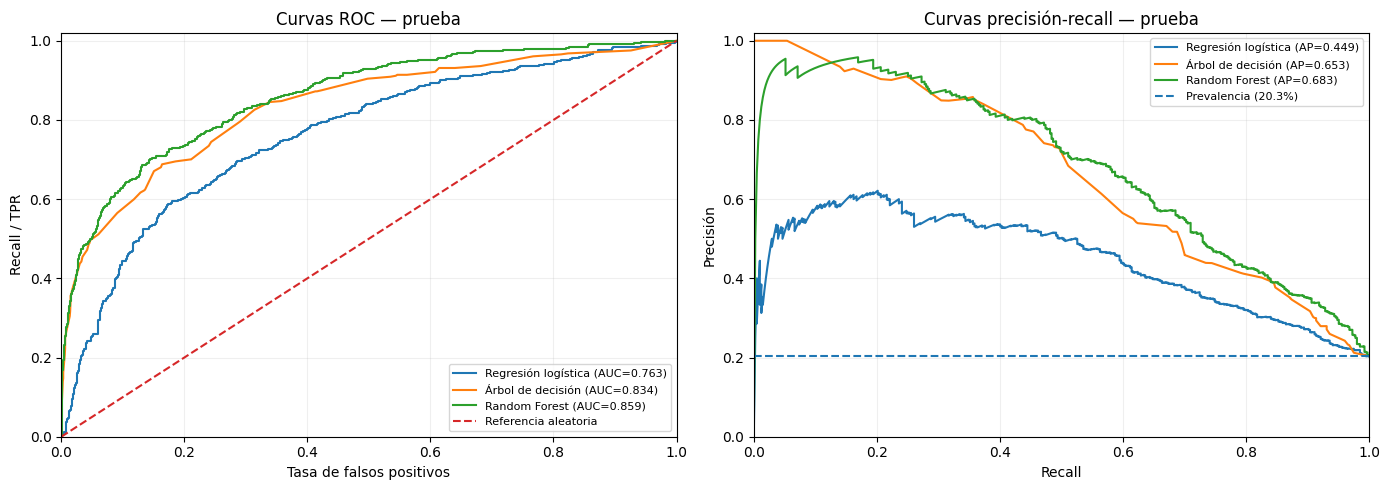

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, proba in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, proba):.3f})")
    axes[1].plot(rec, prec, label=f"{nombre} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", label="Referencia aleatoria")
axes[1].axhline(float(y_test.mean()), linestyle="--", label=f"Prevalencia ({y_test.mean():.1%})")
axes[0].set(title="Curvas ROC — prueba", xlabel="Tasa de falsos positivos", ylabel="Recall / TPR", xlim=(0, 1), ylim=(0, 1.02))
axes[1].set(title="Curvas precisión-recall — prueba", xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 3.4. Incertidumbre: bootstrap de las métricas

Con el enfoque visto en la Práctica 4, tomamos 1.000 muestras de clientes con reemplazo del conjunto de prueba. Los clasificadores permanecen fijos, no hay que reentrenarlos en cada réplica. En cada muestra se calcula F1, precisión y recall; el intervalo del 95 % utiliza los percentiles 2,5 y 97,5.

Para comparar modelos sobre los mismos clientes hacemos un bootstrap pareado: cada réplica usa exactamente los mismos índices para Random Forest y para su comparador. Calculamos la distribución de `F1_RF − F1_otro`, su intervalo y un valor p empírico. Esta comparación no sirve para ajustar nuevamente los modelos sobre prueba.

Un intervalo que incluye 0 no permite afirmar una diferencia estadísticamente clara en F1. Incluso si excluye 0, todavía debe evaluarse si la diferencia es importante económicamente para el banco.

In [22]:
B = 1000
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = np.asarray(y_test, dtype=int)
N_test = len(y_test_arr)
indices_bootstrap = rng.integers(0, N_test, size=(B, N_test))

# Calcular los conteos con NumPy por lotes: mismo bootstrap, sin repetir llamadas costosas a las funciones de scikit-learn para cada réplica.
y_b = y_test_arr[indices_bootstrap]
metricas_bootstrap = ["F1", "Precisión", "Recall"]
distribuciones_bootstrap = {}

for nombre, pred in predicciones_test.items():
    p_b = np.asarray(pred, dtype=int)[indices_bootstrap]
    vp = np.count_nonzero((y_b == 1) & (p_b == 1), axis=1)
    fp = np.count_nonzero((y_b == 0) & (p_b == 1), axis=1)
    fn = np.count_nonzero((y_b == 1) & (p_b == 0), axis=1)

    distribuciones_bootstrap[nombre] = {
        "F1": np.divide(2 * vp, 2 * vp + fp + fn, out=np.zeros(B), where=(2 * vp + fp + fn) != 0),
        "Precisión": np.divide(vp, vp + fp, out=np.zeros(B), where=(vp + fp) != 0),
        "Recall": np.divide(vp, vp + fn, out=np.zeros(B), where=(vp + fn) != 0),
    }

filas_ic = []
for nombre, dist in distribuciones_bootstrap.items():
    for met in metricas_bootstrap:
        li, ls = np.percentile(dist[met], [2.5, 97.5])
        filas_ic.append({
            "Modelo": nombre,
            "Métrica": met,
            "Observado": float(tabla_test.set_index("Modelo").loc[nombre, met]),
            "IC 95 % inferior": li,
            "IC 95 % superior": ls,
            "Amplitud IC": ls - li,
        })

tabla_ic = pd.DataFrame(filas_ic)
display(tabla_ic.round(4))


,Modelo,Métrica,Observado,IC 95 % inferior,IC 95 % superior,Amplitud IC
0,Regresión logística,F1,0.4926,0.4550,0.5229,0.0680
1,Regresión logística,Precisión,0.3828,0.3459,0.4134,0.0675
2,Regresión logística,Recall,0.6904,0.6423,0.7337,0.0914
3,Árbol de decisión,F1,0.5556,0.5186,0.5872,0.0685
4,Árbol de decisión,Precisión,0.4604,0.4195,0.4951,0.0756
5,Árbol de decisión,Recall,0.7002,0.6559,0.7460,0.0901
6,Random Forest,F1,0.6258,0.5821,0.6642,0.0821
7,Random Forest,Precisión,0.6378,0.5853,0.6831,0.0978
8,Random Forest,Recall,0.6143,0.5661,0.6605,0.0944


,Comparación,Diferencia F1 observada,IC 95 % inferior,IC 95 % superior,p bootstrap aproximado,IC excluye cero
0,Random Forest − Regresión logística,0.1332,0.0979,0.1703,0.002,True
1,Random Forest − Árbol de decisión,0.0702,0.0373,0.1026,0.002,True


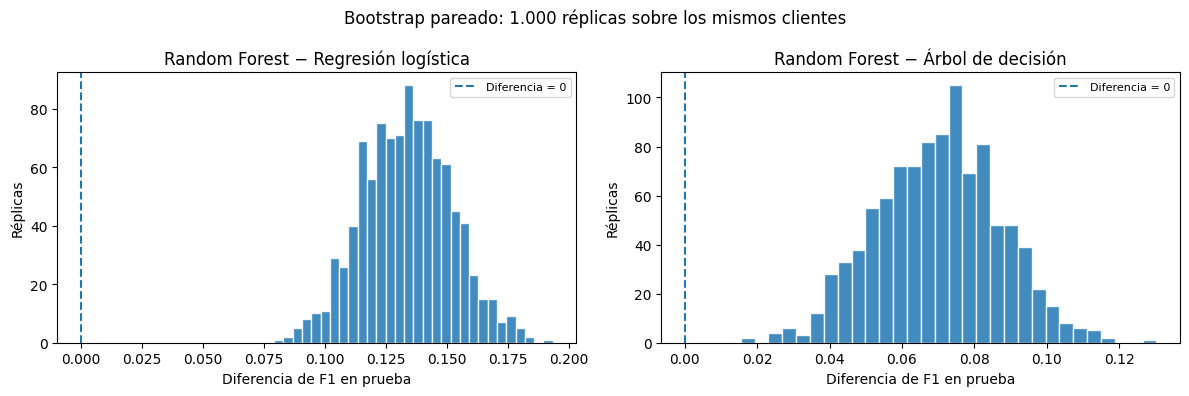

In [23]:
# Comparaciones pareadas de F1 frente al modelo seleccionado, con la misma muestra de clientes.
filas_diferencias = []
diferencias_bootstrap = {}
for otro in [nombre for nombre in mejores_modelos if nombre != nombre_modelo_final]:
    dif = (distribuciones_bootstrap[nombre_modelo_final]["F1"]
           - distribuciones_bootstrap[otro]["F1"])
    diferencias_bootstrap[otro] = dif
    li, ls = np.percentile(dif, [2.5, 97.5])
    f1_rf = tabla_test.set_index("Modelo").loc[nombre_modelo_final, "F1"]
    f1_otro = tabla_test.set_index("Modelo").loc[otro, "F1"]
    # p aproximado bilateral basado en las réplicas: 2*min(fracción <=0, fracción >=0)
    p_aprox = min(1., 2 * (min(np.count_nonzero(dif <= 0), np.count_nonzero(dif >= 0)) + 1) / (B + 1))
    filas_diferencias.append({
        "Comparación": f"{nombre_modelo_final} − {otro}",
        "Diferencia F1 observada": f1_rf - f1_otro,
        "IC 95 % inferior": li,
        "IC 95 % superior": ls,
        "p bootstrap aproximado": p_aprox,
        "IC excluye cero": bool(li > 0 or ls < 0),
    })

tabla_diferencias = pd.DataFrame(filas_diferencias)
display(tabla_diferencias.round(4))

fig, axes = plt.subplots(1, len(diferencias_bootstrap), figsize=(12, 4))
for ax, (otro, dif) in zip(np.atleast_1d(axes), diferencias_bootstrap.items()):
    ax.hist(dif, bins=30, edgecolor="white", alpha=0.85)
    ax.axvline(0, linestyle="--", label="Diferencia = 0")
    ax.set(title=f"Random Forest − {otro}", xlabel="Diferencia de F1 en prueba", ylabel="Réplicas")
    ax.legend(fontsize=8)
plt.suptitle("Bootstrap pareado: 1.000 réplicas sobre los mismos clientes")
plt.tight_layout()
plt.show()


### 3.5. ¿Qué decisiones de entrenamiento pudieron ayudar? ¿Qué debemos mejorar?

Para identificar indicios del efecto de la ponderación de clases, revisamos los resultados de validación cruzada producidos en el punto 2: el mejor F1 disponible entre configuraciones con `class_weight=None` y con `class_weight="balanced"` para cada algoritmo. Este análisis no utiliza prueba ni constituye una comparación causal controlada.

Como oportunidades de mejora, podríamos ajustar el umbral de clasificación usando el conjunto de validación, buscando un mejor equilibrio entre precisión y recall. También sería útil evaluar nuevas características, como las relacionadas con el saldo y la cantidad de productos, e intentar reducir el sobreajuste observado en Random Forest. Finalmente, antes de implementar el modelo en Colombia, sería necesario validarlo con datos de clientes locales.

In [24]:
filas_ponderacion = []
for nombre, busqueda in busquedas.items():
    cv_resultados = pd.DataFrame(busqueda.cv_results_)
    for valor_peso in [None, "balanced"]:
        candidatos = cv_resultados[
            cv_resultados["param_clasificador__class_weight"].apply(lambda v: v == valor_peso)
        ]
        filas_ponderacion.append({
            "Modelo": nombre,
            "Ponderación": "Sin ponderación" if valor_peso is None else "Balanceada",
            "Mejor F1 CV del grupo": candidatos["mean_test_score"].max(),
        })

tabla_ponderacion = pd.DataFrame(filas_ponderacion)
display(tabla_ponderacion.pivot(index="Modelo", columns="Ponderación", values="Mejor F1 CV del grupo").round(4))

# Comparación prueba-validación sin alterar la elección original.
tabla_generalizacion = (tabla_validacion[["Modelo", "F1_validacion", "Precision_validacion", "Recall_validacion"]]
                         .merge(tabla_test[["Modelo", "F1", "Precisión", "Recall"]], on="Modelo"))
tabla_generalizacion["Cambio F1 (test - val)"] = tabla_generalizacion["F1"] - tabla_generalizacion["F1_validacion"]
display(tabla_generalizacion.round(4))


Ponderación,Balanceada,Sin ponderación
Modelo,,
Random Forest,0.6108,0.5681
Regresión logística,0.4954,0.3025
Árbol de decisión,0.5691,0.5533


,Modelo,F1_validacion,Precision_validacion,Recall_validacion,F1,Precisión,Recall,Cambio F1 (test - val)
0,Random Forest,0.5961,0.5918,0.6005,0.6258,0.6378,0.6143,0.0297
1,Árbol de decisión,0.5639,0.4705,0.7034,0.5556,0.4604,0.7002,-0.0083
2,Regresión logística,0.4895,0.3804,0.6863,0.4926,0.3828,0.6904,0.0030


### 3.6. Conclusiones del análisis cuantitativo

**1. Modelo elegido y generalización.** Se mantiene Random Forest, seleccionado previamente con validación. En prueba logra F1 = 0,6258, precisión = 0,6378, recall = 0,6143, exactitud = 0,8505, ROC-AUC = 0,8587 y AP = 0,6832. El F1 de validación era 0,5961: el F1 de prueba es 0,0297 mayor. No se observa una caída entre validación y prueba, pero esto no elimina la señal de sobreajuste que muestra la brecha entre entrenamiento y validación. La exactitud del RF supera el baseline de predecir siempre la clase mayoritaria (0,7965), pero la comparación por F1 es más informativa para los clientes que abandonan.

**2. Errores relevantes para el banco.** De los 407 clientes que abandonaron en prueba, el RF identifica 250 y omite 157. Si se contacta a todos los clasificados como posibles desertores, habría 392 contactos, de los cuales 142 serían innecesarios por corresponder a quienes no iban a abandonar. El árbol detecta 285 desertores (35 adicionales), pero produce 334 falsos positivos (192 adicionales). Por eso no conviene decidir únicamente con recall.

**3. Curvas ROC y precisión-recall.** Las curvas ROC confirman que Random Forest tiene la mayor capacidad de discriminación (AUC = 0,8587), seguido del árbol (0,8339) y la regresión logística (0,7630). Las curvas precisión-recall también favorecen al RF (AP = 0,6832), que mantiene un mejor equilibrio entre detectar desertores y evitar falsos positivos. Esta comparación es especialmente relevante por el desbalance de clases (20,3 % de abandono), ya que permite evaluar el comportamiento de los modelos con distintos umbrales de clasificación.

**4. Incertidumbre y comparación.** Con 1.000 muestras bootstrap, el IC del 95 % del F1 de Random Forest es aproximadamente [0,5821, 0,6642]. El bootstrap pareado compara los tres algoritmos sobre las mismas personas, el F1 del RF supera al del árbol por 0,0702, con IC 95 % de [0,0373, 0,1026], y al de regresión logística por 0,1332, con IC 95 % de [0,0979, 0,1703]. Ambos intervalos excluyen cero. Se trata de evidencia a favor del RF en esta muestra y este protocolo, no de garantía de superioridad en cualquier población.

**5. Decisiones que probablemente favorecieron las métricas.** En la búsqueda de hiperparámetros, la mejor configuración de Random Forest con `class_weight="balanced"` alcanzó F1 CV = 0,6108, frente a 0,5681 de la mejor sin ponderación. Para el árbol, los correspondientes valores fueron 0,5691 y 0,5533. Son comparaciones observacionales entre configuraciones de la búsqueda, no una prueba aislada del efecto de la ponderación. La capacidad de los árboles y ensambles para captar relaciones no lineales es una explicación plausible de su ventaja frente a regresión logística, pero no constituye una prueba de causalidad sobre la mejora.

**Conclusión:** Random Forest ofrece el mejor equilibrio predictivo de los tres modelos con umbral 0,5. Lo conservamos como modelo principal para interpretabilidad y generación de valor, sin asumir todavía que sea el de mayor rentabilidad.

# Punto 4: Análisis cualitativo de resultados del modelo


In [25]:
#%pip install shap lime


In [26]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEMILLA_INTERPRETACION = 42
UMBRAL_INTERPRETACION = 0.5
assert {"Random Forest", "Regresión logística", "Árbol de decisión"}.issubset(mejores_modelos), "Ejecuta primero la preparación y el entrenamiento."
rf_interpretacion = mejores_modelos["Random Forest"]
assert list(rf_interpretacion.classes_) == [0, 1]
# Esta sección llama únicamente transform/predict/predict_proba en los modelos.
# No modifica mejores_modelos, las particiones ni los hiperparámetros.
tiempos_interpretacion = {}

def a_denso(datos):
    return datos.toarray() if hasattr(datos, "toarray") else np.asarray(datos)

def datos_transformados(pipeline, datos):
    prep = pipeline.named_steps["preprocesamiento"]
    nombres = [v.split("__", 1)[-1] for v in prep.get_feature_names_out()]
    return pd.DataFrame(a_denso(prep.transform(datos)), columns=nombres, index=datos.index)


### 4.1. Curvas de expectativa individual (ICE)

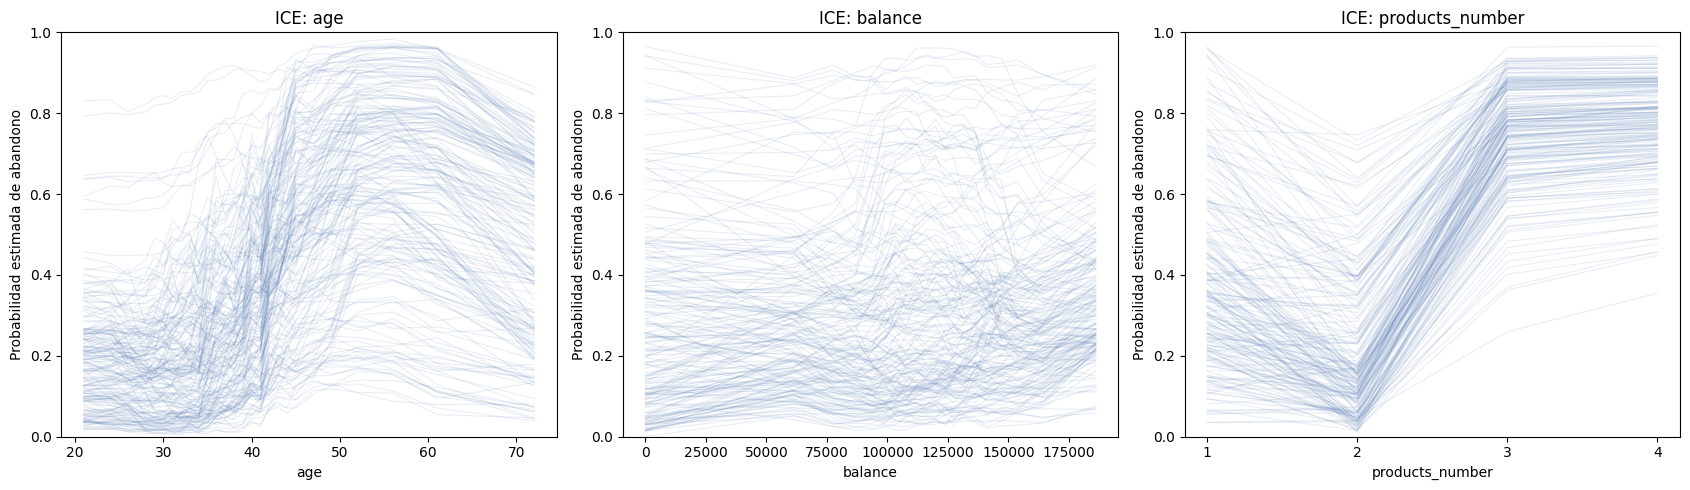

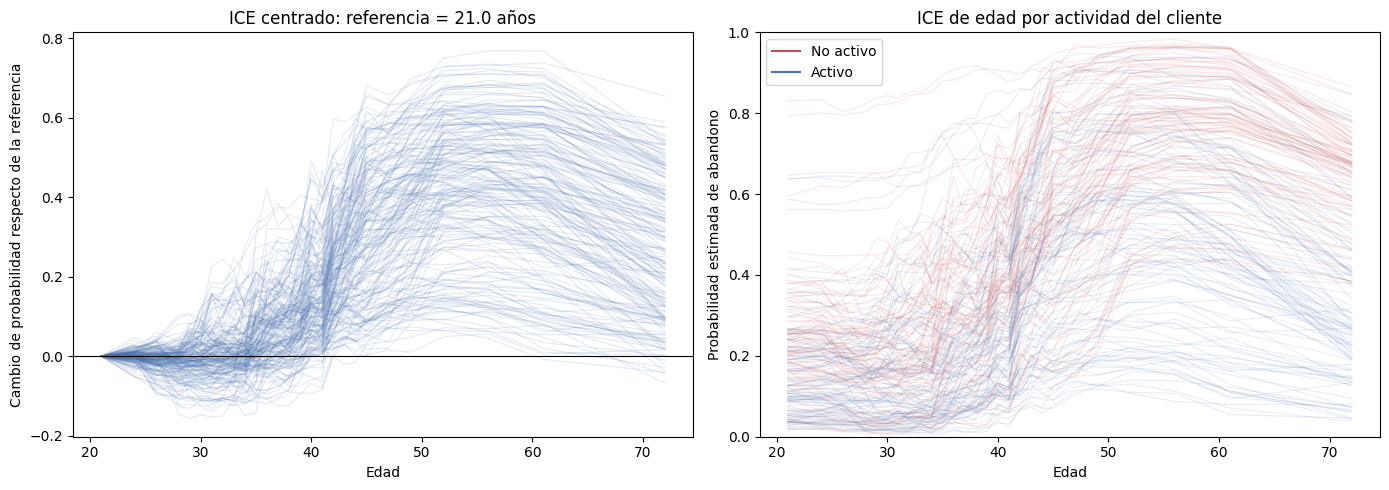

In [27]:
# ICE mediante predict_proba del pipeline, en las unidades originales de X_test.
# Así no dependemos de opciones de rejilla que cambian entre versiones de sklearn.
inicio = time.perf_counter()
clientes_ice = X_test.sample(n=min(200, len(X_test)), random_state=SEMILLA_INTERPRETACION)
rejillas_ice = {
    "age": np.unique(np.quantile(X_train["age"].dropna(), np.linspace(0.01, 0.99, 30))),
    "balance": np.unique(np.quantile(X_train["balance"].dropna(), np.linspace(0.01, 0.99, 30))),
    "products_number": np.array([1, 2, 3, 4]),
}
curvas_ice = {}
for variable, rejilla in rejillas_ice.items():
    columnas = []
    for valor in rejilla:
        escenario = clientes_ice.copy()
        escenario[variable] = valor
        columnas.append(rf_interpretacion.predict_proba(escenario)[:, 1])
    curvas_ice[variable] = np.column_stack(columnas)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (variable, rejilla) in zip(axes, rejillas_ice.items()):
    ax.plot(rejilla, curvas_ice[variable].T, color="#4c72b0", alpha=0.12, linewidth=0.8)
    ax.set(title=f"ICE: {variable}", xlabel=variable, ylabel="Probabilidad estimada de abandono", ylim=(0, 1))
    if variable == "products_number": ax.set_xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()

rejilla_edad = rejillas_ice["age"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
centradas = curvas_ice["age"] - curvas_ice["age"][:, [0]]
axes[0].plot(rejilla_edad, centradas.T, color="#4c72b0", alpha=0.15, linewidth=0.8)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title=f"ICE centrado: referencia = {rejilla_edad[0]:.1f} años", xlabel="Edad", ylabel="Cambio de probabilidad respecto de la referencia")
for valor, color, etiqueta in [(0, "#c44e52", "No activo"), (1, "#4c72b0", "Activo")]:
    mascara = clientes_ice["active_member"].to_numpy() == valor
    if mascara.any():
        axes[1].plot(rejilla_edad, curvas_ice["age"][mascara].T, color=color, alpha=0.12, linewidth=0.8)
        axes[1].plot([], [], color=color, label=etiqueta)
axes[1].set(title="ICE de edad por actividad del cliente", xlabel="Edad", ylabel="Probabilidad estimada de abandono", ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()
tiempos_interpretacion["ICE"] = time.perf_counter() - inicio


- **Lectura de los ejes:** En las gráficas ICE de `age`, `balance` y `products_number`, el eje horizontal muestra los valores de la variable analizada y el eje vertical representa la probabilidad estimada de abandono. Cada curva corresponde a un cliente: se modifica la variable de interés y se mantienen constantes sus demás características. En la gráfica de ICE centrado, el eje vertical muestra el cambio en la probabilidad respecto a la edad de referencia de 21 años. Por su parte, la gráfica de edad por actividad del cliente distingue las curvas de los clientes activos e inactivos mediante colores.
- **Edad:**
    - En la gráfica `ICE: age`, muchas curvas muestran un aumento en la probabilidad estimada de abandono entre los 35 y los 50 años. Esta probabilidad se mantiene elevada hasta cerca de los 60 años y luego disminuye.
    - En la gráfica de ICE centrado, que toma los 21 años como referencia, muchas curvas muestran un incremento en la probabilidad estimada de abandono entre los 40 y aproximadamente los 55 años. El incremento se mantiene elevado hasta cerca de los 60 años y luego se reduce.
- **Productos:** En la gráfica `ICE: products_number`, la probabilidad estimada de abandono tiende a disminuir al pasar de uno a dos productos y a aumentar al pasar de dos a tres. En este último tramo, las pendientes de varias curvas son similares, lo que sugiere que el modelo responde de forma parecida para distintos clientes, aunque la magnitud del cambio varía.
- **Saldo:** En la gráfica `ICE: balance`, las curvas no muestran una tendencia uniforme. Por tanto, un aumento del saldo no se asocia con un incremento o una disminución de la probabilidad estimada de abandono para todos los clientes.
- **Diferencias entre clientes:** Las curvas de edad presentan formas similares entre los 50 y los 70 años, mientras que entre los 30 y los 40 años muestran una mayor diversidad. Esto sugiere que, en este último intervalo, la respuesta del modelo a los cambios de edad varía más según las demás características de cada cliente.
- **Miembros activos e inactivos:** En la gráfica `ICE de edad por actividad del cliente`, no se observa una separación clara entre las curvas de ambos grupos entre los 20 y los 50 años. A partir de los 50 años, las curvas de los clientes inactivos tienden a mostrar probabilidades estimadas de abandono más altas que las de los activos. Sin embargo, persisten superposiciones, especialmente entre 0,4 y 0,6 de probabilidad.

Estas curvas describen el comportamiento predictivo del modelo al modificar una variable y mantener las demás constantes; no permiten establecer relaciones causales sobre el abandono.


### 4.2. Explicaciones locales con LIME

In [28]:
# Selección reproducible de casos que se reutilizarán en SHAP.
prob_casos = rf_interpretacion.predict_proba(X_test)[:, 1]
y_casos = y_test.loc[X_test.index].to_numpy()
pred_casos = (prob_casos >= UMBRAL_INTERPRETACION).astype(int)
rng_casos = np.random.default_rng(SEMILLA_INTERPRETACION)
posiciones_casos = {}
for tipo, mascara in {
    "Verdadero positivo": (y_casos == 1) & (pred_casos == 1),
    "Falso negativo": (y_casos == 1) & (pred_casos == 0),
    "Falso positivo": (y_casos == 0) & (pred_casos == 1),
    "Verdadero negativo": (y_casos == 0) & (pred_casos == 0),
}.items():
    candidatos = np.flatnonzero(mascara)
    if not len(candidatos): raise ValueError(f"No hay casos de tipo {tipo} en prueba.")
    posiciones_casos[tipo] = int(rng_casos.choice(candidatos))
resumen_casos = pd.DataFrame([
    {"Caso": tipo, "Índice": X_test.index[pos], "Clase real": y_casos[pos],
     "Probabilidad de abandono": prob_casos[pos], "Clase predicha": pred_casos[pos]}
    for tipo, pos in posiciones_casos.items()
])
display(resumen_casos)
display(X_test.iloc[list(posiciones_casos.values())])


,Caso,Índice,Clase real,Probabilidad de abandono,Clase predicha
0,Verdadero positivo,8451,1,0.777939,1
1,Falso negativo,7358,1,0.250547,0
2,Falso positivo,175,0,0.647746,1
3,Verdadero negativo,1697,0,0.072627,0


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
8451,588.0,Germany,Female,48.0,1.0,143279.58,2,1,0,31580.80
7358,648.0,France,Female,39.0,6.0,130694.89,2,1,1,153955.38
175,543.0,Spain,Female,41.0,4.0,0.00,1,0,0,194902.16
1697,565.0,France,Male,38.0,5.0,0.00,2,0,1,NaN


Las tablas muestran cuatro clientes seleccionados al azar, uno por cada tipo de resultado: verdadero positivo, falso negativo, falso positivo y verdadero negativo. La primera tabla compara la predicción con el resultado real; la segunda presenta las características de esos mismos clientes. Estas tablas sirven como ejemplo para las explicaciones individuales con LIME y SHAP.


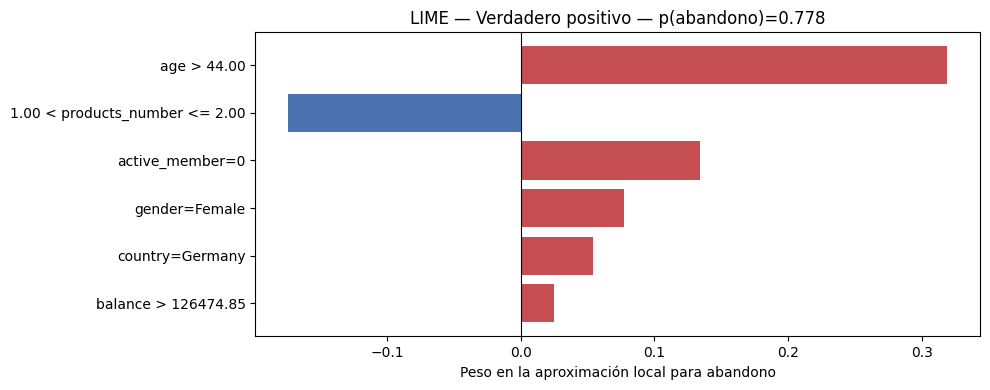

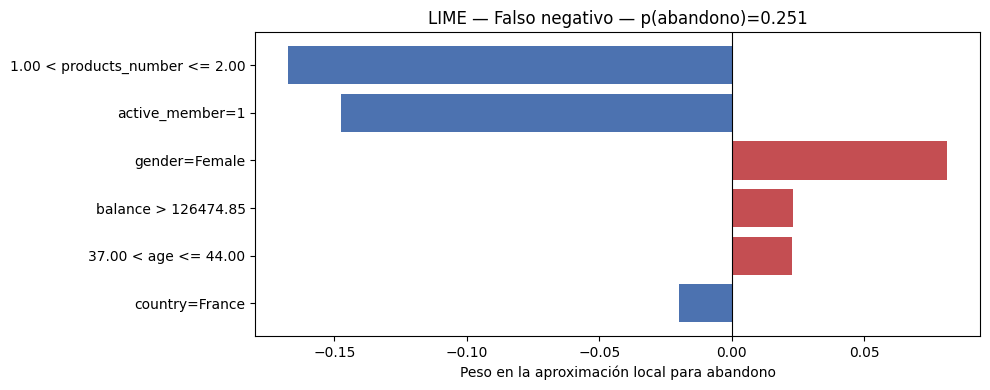

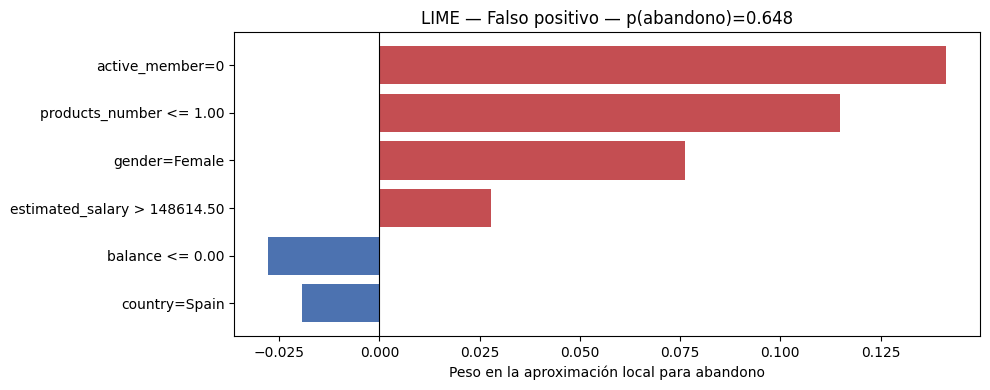

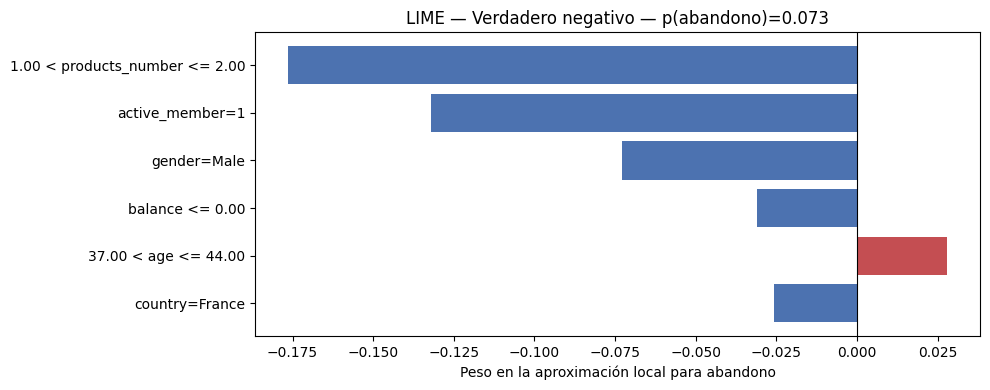

,Caso,Predicción RF,Aproximación local LIME,R² local
0,Verdadero positivo,0.777939,0.651328,0.582318
1,Falso negativo,0.250547,0.240041,0.278930
2,Falso positivo,0.647746,0.495453,0.186164
3,Verdadero negativo,0.072627,0.123474,0.268427


In [29]:
from lime.lime_tabular import LimeTabularExplainer

# LIME utiliza numéricas imputadas en unidades originales y categorías originales.
# La función de predicción aplica el pipeline ya ajustado, sin entrenarlo.
prep_lime = rf_interpretacion.named_steps["preprocesamiento"]
escalador_lime = prep_lime.named_transformers_["numericas"].named_steps["escalado"]
slice_num_lime = prep_lime.output_indices_["numericas"]
# Agrupar las columnas one-hot por variable para evitar que las perturbaciones
# creen clientes con dos países a la vez o sin país. Se explican categorías originales.
ohe_lime = prep_lime.named_transformers_["categoricas"]
slice_cat_lime = prep_lime.output_indices_["categoricas"]
columnas_lime = list(numericas) + list(binarias) + list(categoricas)

def preparar_lime(datos):
    transformados = datos_transformados(rf_interpretacion, datos).to_numpy().copy()
    num_original = escalador_lime.inverse_transform(transformados[:, slice_num_lime])
    bin_original = transformados[:, prep_lime.output_indices_["binarias"]]
    categorias_originales = ohe_lime.inverse_transform(transformados[:, slice_cat_lime])
    codigos = np.column_stack([
        pd.Categorical(categorias_originales[:, j], categories=cats).codes
        for j, cats in enumerate(ohe_lime.categories_)
    ])
    return np.column_stack([num_original, bin_original, codigos]).astype(float)

train_lime_original = preparar_lime(X_train)
test_lime_original = preparar_lime(X_test)
indices_cat_original = list(range(len(numericas), len(columnas_lime)))
nombres_cat_original = {len(numericas) + j: ["0", "1"] for j in range(len(binarias))}
for j, cats in enumerate(ohe_lime.categories_):
    nombres_cat_original[len(numericas) + len(binarias) + j] = list(map(str, cats))

def predecir_lime(valores):
    tabla = pd.DataFrame(np.asarray(valores), columns=columnas_lime)
    for j, variable in enumerate(categoricas):
        codigos = np.rint(tabla[variable].to_numpy()).astype(int)
        tabla[variable] = np.asarray(ohe_lime.categories_[j])[codigos]
    return rf_interpretacion.predict_proba(tabla[X_train.columns])

np.testing.assert_allclose(predecir_lime(test_lime_original), rf_interpretacion.predict_proba(X_test), atol=1e-10)

def crear_lime(semilla):
    return LimeTabularExplainer(
        training_data=train_lime_original, feature_names=columnas_lime,
        categorical_features=indices_cat_original, categorical_names=nombres_cat_original,
        class_names=["Permanece", "Abandona"], mode="classification",
        discretize_continuous=True, random_state=semilla,
    )

inicio = time.perf_counter()
explicador_lime = crear_lime(SEMILLA_INTERPRETACION)
explicaciones_lime = {}
filas_fidelidad = []
for tipo, pos in posiciones_casos.items():
    explicacion = explicador_lime.explain_instance(
        test_lime_original[pos], predecir_lime, labels=(1,), num_features=6, num_samples=5000)
    explicaciones_lime[tipo] = explicacion
    condiciones = explicacion.as_list(label=1)
    etiquetas, pesos = zip(*condiciones)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(etiquetas, pesos, color=["#c44e52" if v > 0 else "#4c72b0" for v in pesos])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=f"LIME — {tipo} — p(abandono)={prob_casos[pos]:.3f}", xlabel="Peso en la aproximación local para abandono")
    plt.tight_layout()
    plt.show()
    filas_fidelidad.append({"Caso": tipo, "Predicción RF": prob_casos[pos],
                            "Aproximación local LIME": float(np.ravel(explicacion.local_pred)[0]),
                            "R² local": explicacion.score})
display(pd.DataFrame(filas_fidelidad))
tiempos_interpretacion["LIME (4 casos)"] = time.perf_counter() - inicio


- **Lectura de los ejes:** En las gráficas LIME, el eje vertical presenta las seis condiciones seleccionadas para explicar cada predicción y el eje horizontal muestra sus pesos en la aproximación local para la predicción de abandono de ese cliente. Se muestran las seis condiciones seleccionadas por LIME para esa explicación local, no las características más importantes del modelo en general. Las barras rojas tienen pesos positivos y por lo tanto favorecen el abandono, y las azules tienen peso negativo y favorecen la permanencia. La longitud de cada barra indica la magnitud del peso.

- **Verdadero positivo:** Para el cliente con índice 8451, que efectivamente abandonó, el modelo estima una probabilidad de abandono de 0,778. La condición `age > 44` presenta el mayor peso positivo, seguida de `active_member=0`. Las condiciones `gender=Female`, `country=Germany` y un saldo superior a 126474,85 también favorecen el abandono, aunque con pesos menores. En cambio, tener dos productos presenta un peso negativo. En conjunto, la explicación local es coherente con la clasificación correcta del cliente como un caso de abandono.

- **Falso negativo:** Para el cliente con índice 7358, que abandonó pero fue clasificado como un caso de permanencia, la probabilidad estimada de abandono es de 0,251. Tener dos productos y ser un miembro activo son las condiciones con mayores pesos negativos. Aunque `gender=Female`, el saldo superior a 126474,85 y la edad entre 37 y 44 años presentan pesos positivos, la aproximación local asigna una probabilidad baja de abandono. Las características que favorecen la permanencia en la explicación local se presentaron en un cliente que decició abandonar, lo cual ayuda a explicar dónde pudo surgir el error. 

- **Falso positivo:** Para el cliente con índice 175, que permaneció pero fue clasificado como un caso de abandono, el modelo estima una probabilidad de 0,648. La inactividad y tener un solo producto presentan los mayores pesos positivos, seguidos de `gender=Female` y un salario estimado superior a 148614,50. Por su parte, el saldo igual a cero y `country=Spain` tienen pesos negativos. Estas condiciones ayudan a describir la orientación de la explicación, pero su fidelidad es limitada en este caso.

- **Verdadero negativo:** Para el cliente con índice 1697, que permaneció y fue clasificado como un caso de permanencia, el modelo estima una probabilidad de abandono de 0,073. Tener dos productos, ser un miembro activo, la condición `gender=Male`, el saldo igual a cero y `country=France` presentan pesos negativos en la explicación local. La condición de edad entre 37 y 44 años presenta un peso positivo. En conjunto, la aproximación de LIME es coherente con la clasificación del cliente como un caso de permanencia.

- **Fidelidad de las explicaciones:** Para el verdadero positivo, LIME estima una probabilidad de 0,651 frente a 0,778 del Random Forest, con un R² local de 0,582. En el falso negativo, ambas probabilidades son cercanas (0,240 y 0,251), pero el R² local es de 0,279: aproximar bien la predicción de ese cliente no implica reproducir bien el comportamiento del modelo en su vecindario. El falso positivo presenta la menor fidelidad, con un R² local de 0,186 y una probabilidad aproximada de 0,495 frente a 0,648 del Random Forest. Por tanto, sus pesos deben ser interpretados con más cautela. 

In [30]:
# Estabilidad: mismo cliente, cinco semillas y dos tamaños del vecindario.
filas_estabilidad = []
pos_estabilidad = posiciones_casos["Verdadero positivo"]
for cantidad in [1000, 5000]:
    for semilla in range(5):
        explicacion = crear_lime(semilla).explain_instance(
            test_lime_original[pos_estabilidad], predecir_lime,
            labels=(1,), num_features=6, num_samples=cantidad)
        for condicion, peso in explicacion.as_list(label=1):
            filas_estabilidad.append({"Muestras": cantidad, "Semilla": semilla,
                                      "Condición": condicion, "Peso": peso})
estabilidad_lime = pd.DataFrame(filas_estabilidad)
display(estabilidad_lime.pivot_table(index="Condición", columns=["Muestras", "Semilla"], values="Peso"))
# NaN indica que esa condición no quedó entre las seis seleccionadas en la repetición.


Muestras                             1000                                \
Semilla                                 0         1         2         3   
Condición                                                                 
1.00 < products_number <= 2.00  -0.150283 -0.160070 -0.150126 -0.162297   
586.00 < credit_score <= 652.00       NaN       NaN       NaN -0.029228   
active_member=0                  0.137395  0.139006  0.141214  0.144327   
age > 44.00                      0.317832  0.318909  0.314104  0.321426   
balance > 126474.85              0.017519  0.031784  0.020214       NaN   
country=Germany                  0.035980  0.043542  0.023378  0.050919   
gender=Female                    0.071701  0.070747  0.085635  0.083575   

Muestras                                       5000                      \
Semilla                                 4         0         1         2   
Condición                                                                 
1.00 < products_number <= 2.00  -0.172187 -0.166592 -0.166564 -0.166824   
586.00 < credit_score <= 652.00       NaN       NaN       NaN       NaN   
active_member=0                  0.146357  0.143045  0.147098  0.135947   
age > 44.00                      0.326028  0.313341  0.317985  0.315150   
balance > 126474.85              0.048349  0.019289  0.032114  0.037774   
country=Germany                  0.046713  0.042140  0.055718  0.046706   
gender=Female                    0.097921  0.077782  0.077785  0.080712   

Muestras                                             
Semilla                                 3         4  
Condición                                            
1.00 < products_number <= 2.00  -0.170793 -0.167409  
586.00 < credit_score <= 652.00       NaN       NaN  
active_member=0                  0.136991  0.143902  
age > 44.00                      0.311964  0.313445  
balance > 126474.85              0.027149  0.027316  
country=Germany                  0.049817  0.047767  
gender=Female                    0.077852  0.081150

- **Estabilidad de los resultados:** Para el verdadero positivo se repitió la explicación con cinco semillas y con 1000 y 5000 muestras de perturbación. La edad superior a 44 años conserva el mayor peso positivo, la inactividad mantiene un peso positivo y tener dos productos mantiene un peso negativo. Con 5000 muestras, los pesos de estas condiciones varían menos entre semillas. Las condiciones con menor peso son más sensibles al muestreo: con 1000 muestras, el intervalo de puntaje crediticio aparece en una repetición y sustituye al saldo entre las seis condiciones con mayor influencia. Los valores `NaN` indican que una condición no fue seleccionada, no que su peso sea cero. Esta evidencia de estabilidad se limita al cliente analizado.

### 4.3. Valores SHAP: predicciones individuales



/Users/laurafonseca/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Valor base SHAP,Prevalencia de entrenamiento,Promedio RF en el fondo,class_weight
0,0.499136,0.203667,0.304652,balanced


Verdadero positivo | índice 8451 | real=1 | p=0.7779


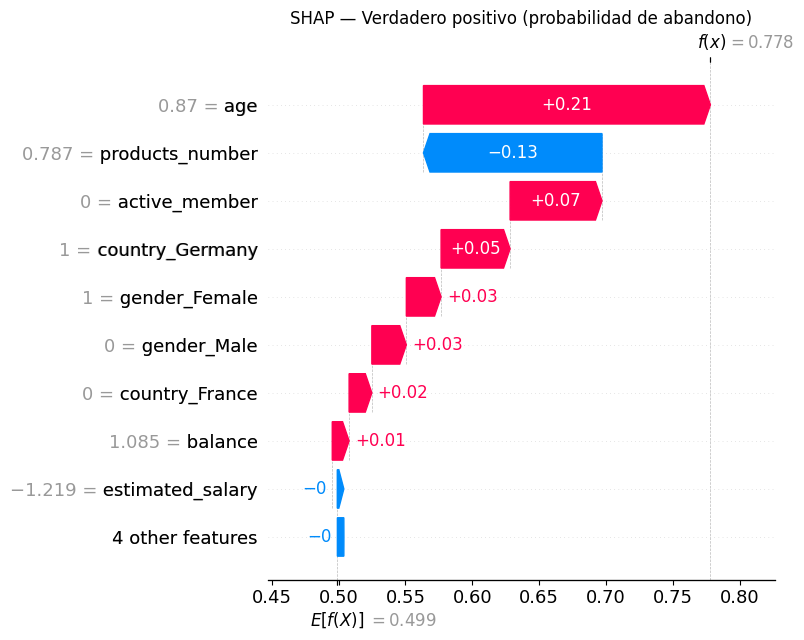

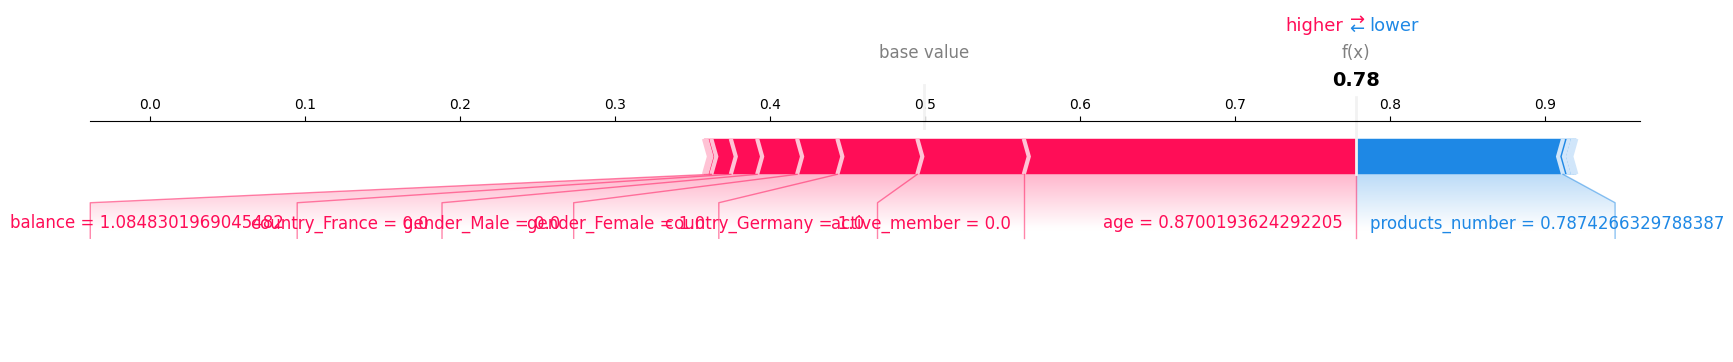

Falso negativo | índice 7358 | real=1 | p=0.2505


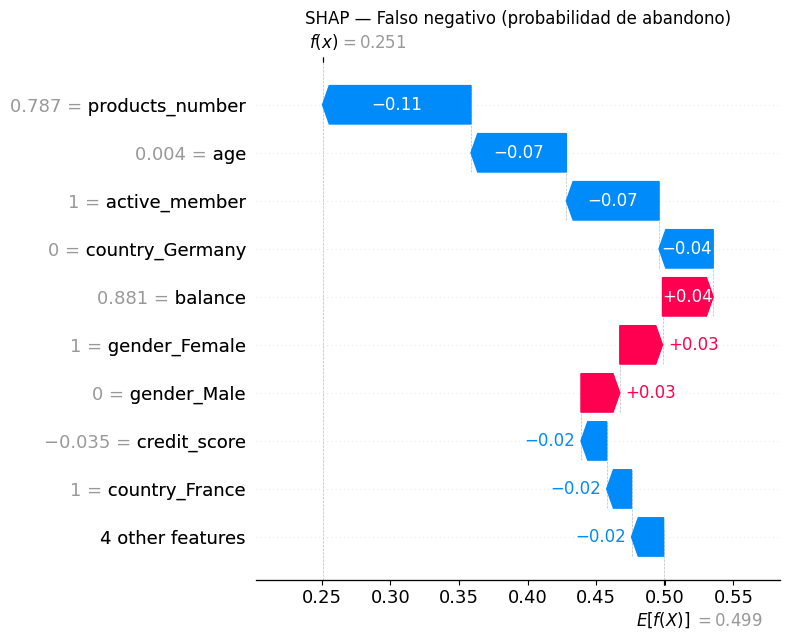

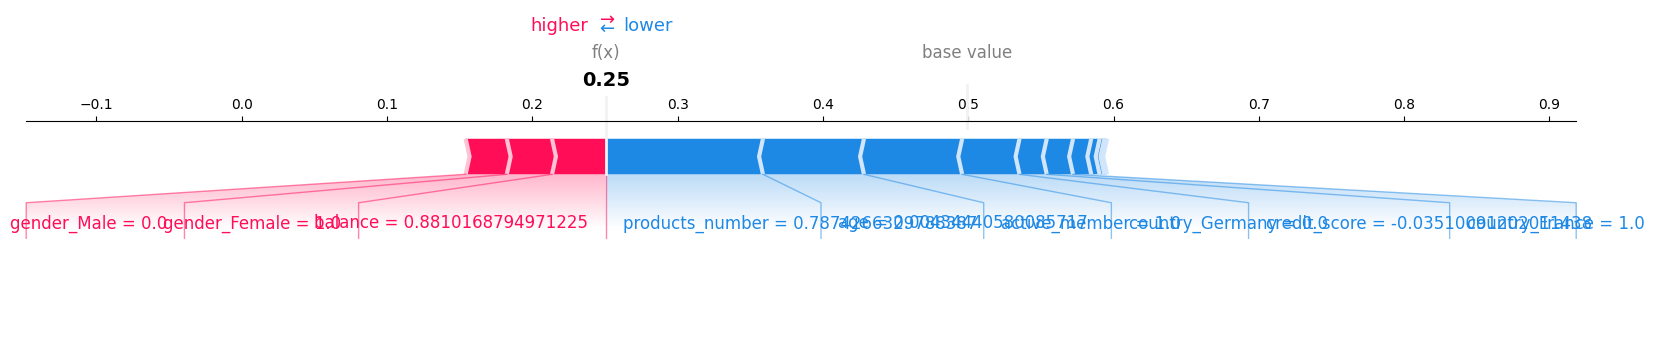

Falso positivo | índice 175 | real=0 | p=0.6477


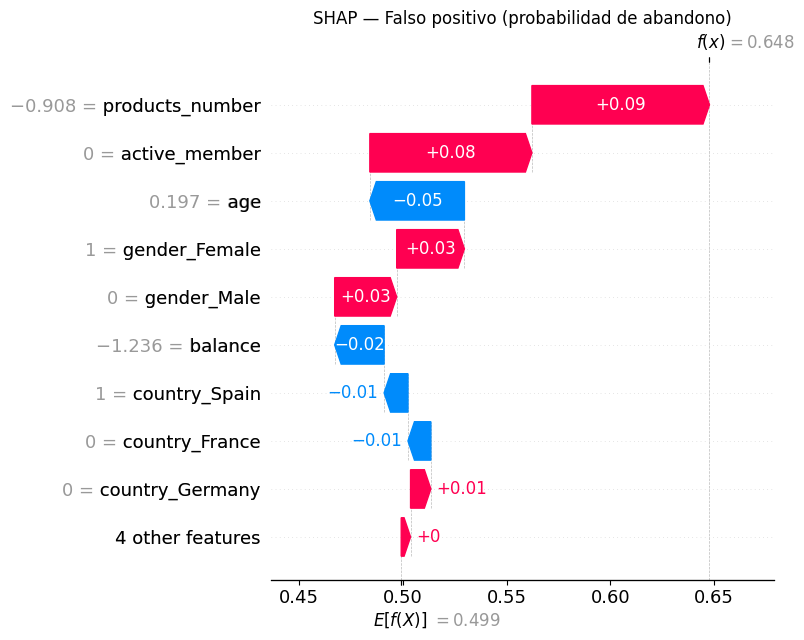

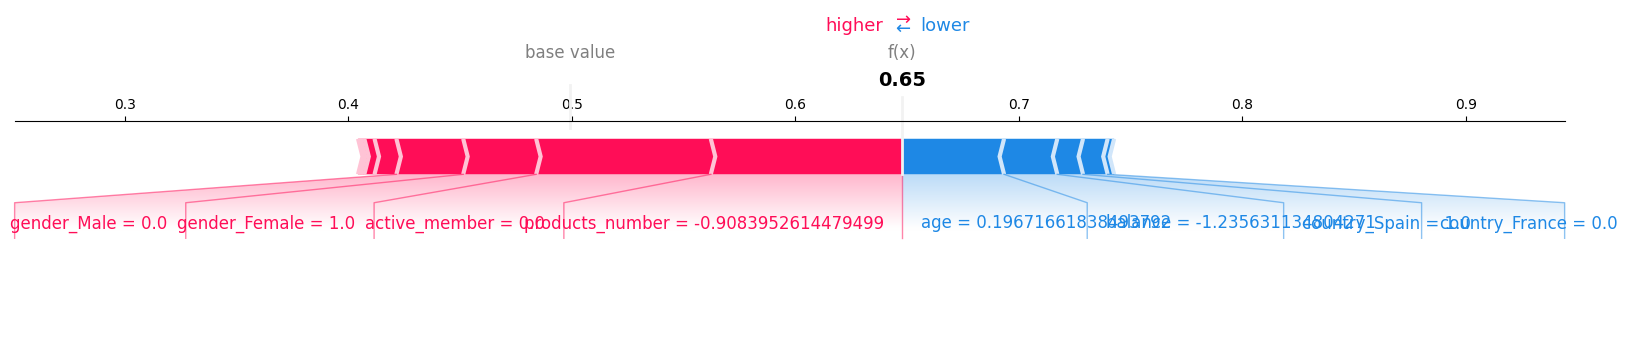

Verdadero negativo | índice 1697 | real=0 | p=0.0726


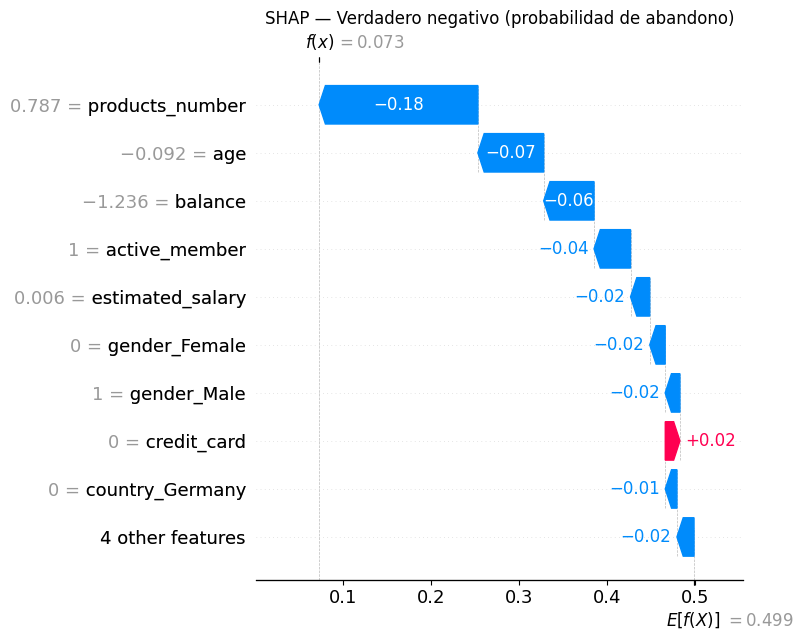

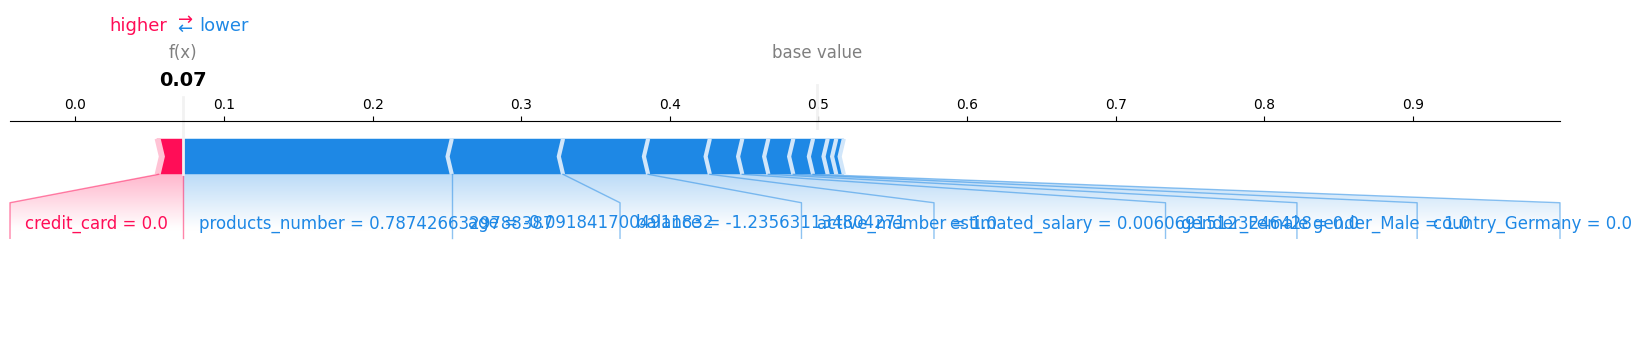

In [31]:
import shap

# Misma muestra para los tres modelos, incluyendo los casos locales elegidos.
inicio = time.perf_counter()
rng_shap = np.random.default_rng(SEMILLA_INTERPRETACION)
obligatorias = np.array(list(posiciones_casos.values()))
restantes = np.setdiff1d(np.arange(len(X_test)), obligatorias)
n_shap = min(300, len(X_test))
posiciones_shap = np.concatenate([obligatorias, rng_shap.choice(restantes, size=n_shap-len(obligatorias), replace=False)])
clientes_shap = X_test.iloc[posiciones_shap]
fondo_shap = X_train.sample(n=min(100, len(X_train)), random_state=SEMILLA_INTERPRETACION)
X_shap_rf = datos_transformados(rf_interpretacion, clientes_shap)
fondo_shap_rf = datos_transformados(rf_interpretacion, fondo_shap)

# En clasificadores sklearn, TreeExplainer con salida raw explica
# las probabilidades de las clases. La referencia usa las rutas de entrenamiento.
explicador_shap_rf = shap.TreeExplainer(
    rf_interpretacion.named_steps["clasificador"],
    feature_perturbation="tree_path_dependent", model_output="raw")

def explicacion_clase1(explicador, datos):
    valores = explicador(datos)
    if valores.values.ndim == 3:
        valores = valores[:, :, 1]
    return valores

shap_rf = explicacion_clase1(explicador_shap_rf, X_shap_rf)
prob_shap_rf = rf_interpretacion.predict_proba(clientes_shap)[:, 1]
np.testing.assert_allclose(shap_rf.base_values + shap_rf.values.sum(axis=1), prob_shap_rf, atol=1e-5)
display(pd.DataFrame({
    "Valor base SHAP": [float(np.mean(shap_rf.base_values))],
    "Prevalencia de entrenamiento": [float(y_train.mean())],
    "Promedio RF en el fondo": [float(rf_interpretacion.predict_proba(fondo_shap)[:, 1].mean())],
    "class_weight": [rf_interpretacion.named_steps["clasificador"].class_weight],
}))

for tipo, pos in posiciones_casos.items():
    fila = int(np.flatnonzero(posiciones_shap == pos)[0])
    print(f"{tipo} | índice {X_test.index[pos]} | real={y_casos[pos]} | p={prob_casos[pos]:.4f}")
    shap.plots.waterfall(shap_rf[fila], max_display=10, show=False)
    plt.title(f"SHAP — {tipo} (probabilidad de abandono)")
    plt.tight_layout()
    plt.show()
    shap.plots.force(shap_rf[fila], matplotlib=True, show=False)
    plt.show()
tiempos_interpretacion["SHAP RF (300 clientes)"] = time.perf_counter() - inicio
# Los valores numéricos mostrados en las características SHAP están estandarizados;
# las contribuciones y el valor base del Forest están en escala de probabilidad.


- **Valor base:** La explicación parte de un valor de 0,499, aproximadamente 49,9 %. Desde allí, las características de cada cliente aumentan o reducen la predicción. Este valor no es la tasa real de abandono, cercana al 20 %: es una referencia del modelo, influida por el mayor peso que recibieron los clientes que abandonan durante el entrenamiento.
- **Unidades:** Las barras rojas aumentan la probabilidad estimada de abandono y las azules la reducen. Por ejemplo, una contribución de +0,21 suma aproximadamente 21 puntos porcentuales. El valor base más todas las contribuciones da la probabilidad final. Los números junto a las características están transformados; por ejemplo, el valor mostrado de edad no está directamente en años.
- **Caso verdadero positivo:** Para el cliente 8451, que abandonó, el modelo estima una probabilidad de 77,8 %. Su edad de 48 años, la inactividad y pertenecer a Alemania elevan la predicción. Tener dos productos la reduce, pero predominan las señales de abandono y el modelo acierta.
- **Caso falso negativo:** Para el cliente 7358, que abandonó, el modelo estima una probabilidad de solo 25,1 %. Tener dos productos, ser activo y su edad de 39 años reducen la predicción. Aunque otras características la aumentan, no compensan esas reducciones y el modelo predice permanencia de forma equivocada.
- **Caso verdadero negativo:** Para el cliente 1697, que permaneció, el modelo estima una probabilidad de abandono de 7,3 %. Tener dos productos, su edad de 38 años, el saldo cero y ser activo reducen la predicción y ayudan a explicar el acierto. El salario no estaba registrado: el valor mostrado para esa característica fue completado durante la preparación de los datos.
- **Caso falso positivo:** Para el cliente 175, que permaneció, el modelo estima una probabilidad de abandono de 64,8 %. Tener un solo producto y ser inactivo son las señales que más elevan la predicción. La edad de 41 años y el saldo cero la reducen, pero predominan las señales de abandono y se genera una falsa alarma.
- **Comparación con LIME:** Ambas técnicas coinciden en varias señales importantes, como la inactividad y tener un solo producto a favor del abandono, o tener dos productos y ser activo en sentido contrario. Sin embargo, no siempre coinciden: para el falso negativo, LIME asigna a su intervalo de edad un peso positivo y SHAP muestra una contribución negativa. Esto puede ocurrir porque construyen las explicaciones de maneras diferentes. Además, la explicación de LIME para el falso positivo reproduce poco fielmente al modelo, por lo que debe interpretarse con cuidado. Ninguna técnica demuestra las causas reales del abandono.


### 4.4. Valores SHAP: comportamiento global

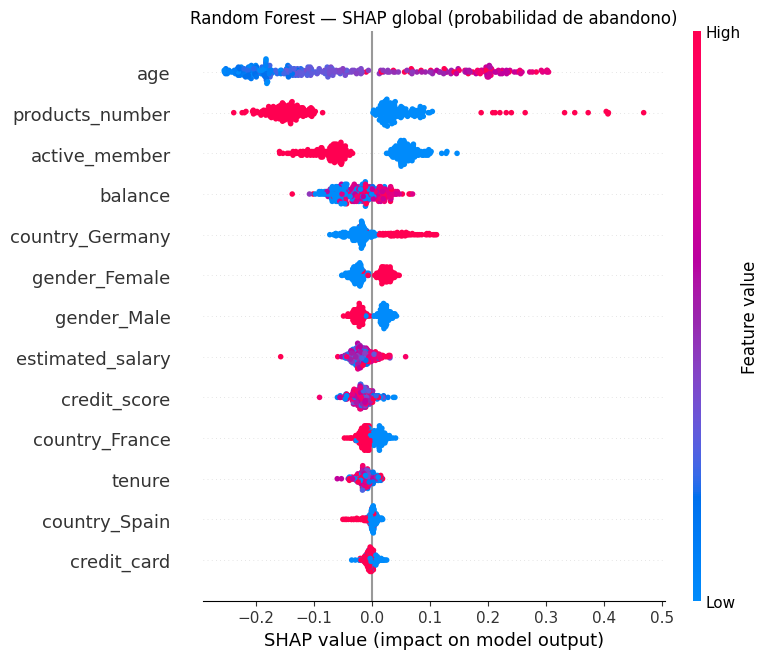

In [32]:
shap.plots.beeswarm(shap_rf, max_display=15, show=False)
plt.title("Random Forest — SHAP global (probabilidad de abandono)")
plt.tight_layout()
plt.show()

# Visualización interactiva: requiere un notebook de confianza y soporte JavaScript.
# Cada columna del gráfico conjunto corresponde a un cliente explicado.
shap.initjs()
display(shap.plots.force(
    float(shap_rf.base_values[0]), shap_rf.values, X_shap_rf,
    feature_names=list(X_shap_rf.columns), matplotlib=False))


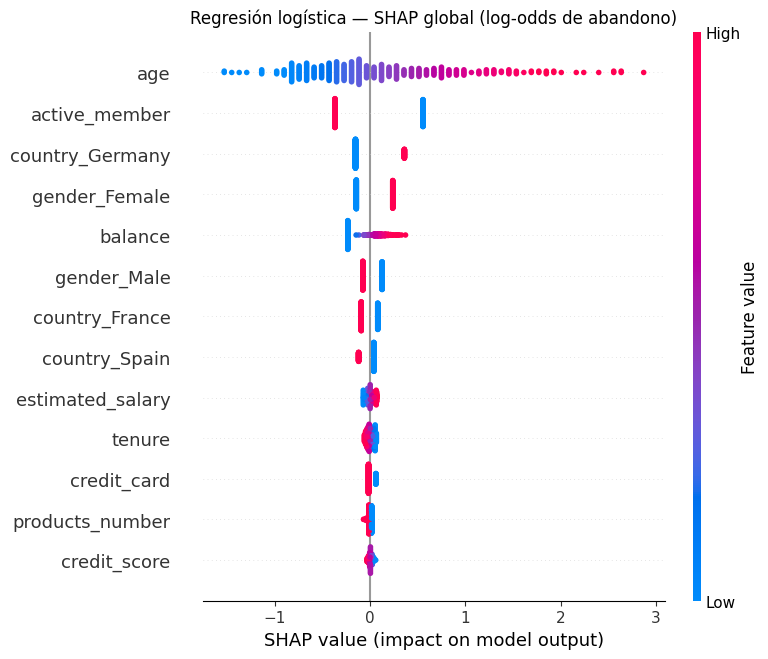

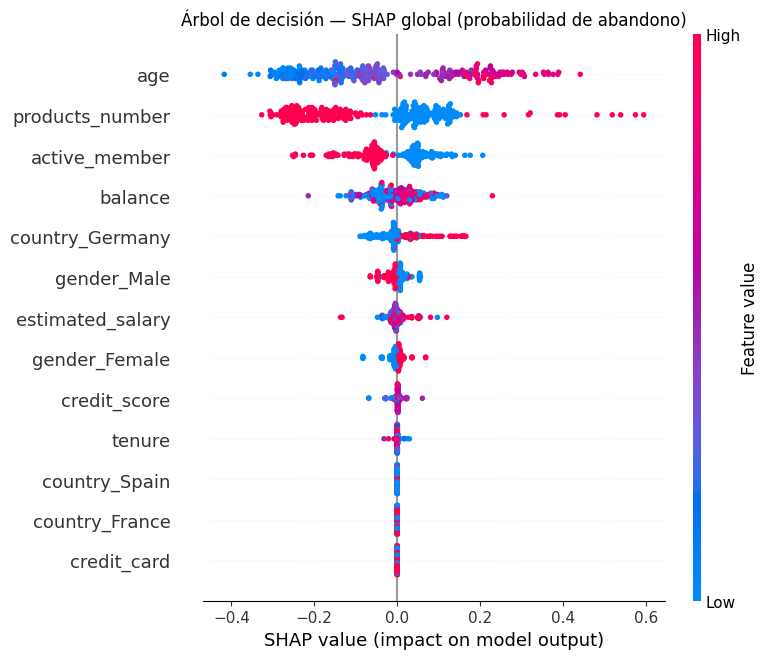

Posición en el ranking de magnitud SHAP media (1 = primera):


,Random Forest,Regresión logística,Árbol de decisión
Característica transformada,,,
age,1.0,1.0,1.0
products_number,2.0,12.0,2.0
active_member,3.0,2.0,3.0
balance,4.0,5.0,4.0
country_Germany,5.0,3.0,5.0
gender_Female,6.0,4.0,8.0
gender_Male,7.0,6.0,6.0
estimated_salary,8.0,9.0,7.0
credit_score,9.0,13.0,9.0


In [33]:
# Comparación global: árbol en probabilidad y logística en log-odds.
# No comparar la magnitud horizontal entre escalas distintas.
explicaciones_shap_modelos = {"Random Forest": shap_rf}
for nombre in ["Regresión logística", "Árbol de decisión"]:
    pipeline = mejores_modelos[nombre]
    datos = datos_transformados(pipeline, clientes_shap)
    fondo = datos_transformados(pipeline, fondo_shap)
    clasificador = pipeline.named_steps["clasificador"]
    if nombre == "Regresión logística":
        explicador = shap.LinearExplainer(clasificador, fondo)
        explicacion = explicador(datos)
        referencia = pipeline.decision_function(clientes_shap)
        escala = "log-odds de abandono"
    else:
        explicador = shap.TreeExplainer(clasificador,
            feature_perturbation="tree_path_dependent", model_output="raw")
        explicacion = explicacion_clase1(explicador, datos)
        referencia = pipeline.predict_proba(clientes_shap)[:, 1]
        escala = "probabilidad de abandono"
    np.testing.assert_allclose(explicacion.base_values + explicacion.values.sum(axis=1), referencia, atol=1e-5)
    explicaciones_shap_modelos[nombre] = explicacion
    shap.plots.beeswarm(explicacion, max_display=15, show=False)
    plt.title(f"{nombre} — SHAP global ({escala})")
    plt.tight_layout()
    plt.show()

ranking_shap = pd.DataFrame({
    nombre: pd.Series(np.abs(explicacion.values).mean(axis=0), index=explicacion.feature_names).rank(ascending=False, method="min")
    for nombre, explicacion in explicaciones_shap_modelos.items()
}).sort_values("Random Forest")
ranking_shap.index.name = "Característica transformada"
print("Posición en el ranking de magnitud SHAP media (1 = primera):")
display(ranking_shap)


- **Lectura del enjambre:** Cada punto representa a un cliente. El rojo indica valores altos de una característica y el azul valores bajos. Los puntos a la derecha de cero aumentan la predicción de abandono y los de la izquierda la reducen. Cuanto más lejos estén de cero, mayor es su aporte a la predicción.
- **Características principales:** En el Random Forest destacan la edad, el número de productos, la actividad del cliente y el saldo. Son las características que más contribuyen, en promedio, a las predicciones de los clientes analizados.
- **Dirección:** Las edades altas tienden a aumentar la predicción de abandono, mientras que ser un miembro activo suele reducirla. El número de productos no sigue una única dirección: como muestran las curvas ICE, dos productos suelen reducir el riesgo estimado y tres o cuatro lo aumentan. En el saldo, el cambio varía entre clientes.
- **Grupos:** Se observan clientes con señales parecidas, como edades que elevan el riesgo estimado o una actividad que lo reduce. Sin embargo, cada cliente combina señales distintas. Estas gráficas ayudan a reconocer perfiles, pero no establecen grupos definitivos.
- **Comparación entre modelos:** La edad ocupa el primer lugar en los tres modelos. El árbol y el Random Forest también coinciden en destacar los productos y la actividad. En cambio, los productos tienen poca importancia en la regresión logística. No se comparan directamente los tamaños de las contribuciones entre los tres, porque la gráfica de regresión logística utiliza una escala diferente.
- **Coherencia con ICE y casos individuales:** Los resultados coinciden con varios patrones anteriores: tener dos productos y ser un miembro activo suelen reducir la predicción de abandono. Esto se observa también en los casos individuales, aunque esas señales no garantizan un acierto: el cliente del falso negativo tenía ambas características y finalmente abandonó.


### 4.5. Síntesis y limitaciones


In [34]:
# Tiempos registrados; no incluye las repeticiones de estabilidad de LIME.
claves_tiempos = ["ICE", "LIME (4 casos)", "SHAP RF (300 clientes)"]
display(pd.Series({clave: tiempos_interpretacion[clave] for clave in claves_tiempos
                   if clave in tiempos_interpretacion}, name="Segundos observados").to_frame())


,Segundos observados
ICE,1.188302
LIME (4 casos),0.758652
SHAP RF (300 clientes),9.145573


| Técnica | ¿Para qué sirve? | Principal cuidado |
|---|---|---|
| ICE | Ver cómo cambia la predicción al variar una característica de un cliente. | Los cambios simulados pueden crear perfiles poco realistas. |
| LIME | Identificar las condiciones que ayudan a explicar una predicción individual. | La explicación es aproximada y puede cambiar entre repeticiones. |
| SHAP | Mostrar qué características aumentan o reducen cada predicción y comparar patrones entre clientes. | Sus aportes explican al modelo, no las causas reales del abandono. |

- **Funcionamiento del modelo:** La edad, el número de productos, la actividad y el saldo son las características principales del Random Forest. Tener dos productos y ser un miembro activo suelen reducir el riesgo estimado. El efecto del saldo varía entre clientes.
- **Aciertos y errores:** Las mismas señales pueden aparecer en predicciones correctas y equivocadas. Por ejemplo, tener dos productos reduce el riesgo estimado tanto en clientes que permanecieron como en uno que abandonó. Por eso, ninguna característica permite asegurar qué hará el cliente.
- **Utilidad para el banco:** Las explicaciones pueden ayudar a un asesor a entender por qué el modelo identifica a un cliente como un posible caso de abandono. Sirven para orientar la revisión del caso, pero no garantizan que una oferta logre retenerlo.
- **Sobreajuste:** El modelo obtuvo un F1 de 0,9360 en entrenamiento y de 0,5961 en validación. Esta diferencia muestra que funciona mucho mejor con los clientes usados para aprender que con clientes nuevos. Las gráficas explican sus decisiones, pero no resuelven esta limitación.
- **Causalidad y generalización:** Estas técnicas muestran cómo decide el modelo, no por qué una persona abandona realmente. Además, los resultados se basan en una muestra y en datos europeos; antes de aplicarlos en Colombia habría que comprobar su desempeño con clientes locales.


# Punto 5: Generación de valor

El objetivo es estimar cuánto podría ganar un banco al usar el modelo para orientar una campaña de retención y cuándo recuperaría la inversión. Se utiliza la matriz de confusión de prueba, con el umbral de 0,5 y sin entrenar nuevamente ni cambiar el modelo por sus resultados de prueba.

Se sigue la fórmula de valor esperado de Provost de las diapositivas de **Métricas avanzadas y generación de valor**, páginas 21–28, y de la [Práctica 4, actividad 3](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-4/actividad-3/). La [ayuda de impacto de negocio](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/impacto-negocio/) distingue la ganancia por cliente evaluado, la ganancia por contacto y la inversión del proyecto.

### 5.1. Supuestos, datos y fuentes

Se analiza la **cartera de 20.000 clientes exigida por el enunciado**. Para este ejercicio, las características promedio se representan con un único valor recuperable por cliente, un costo medio de contacto y las proporciones de aciertos y errores de prueba. Todos los valores monetarios están en COP nominales, sin descuento financiero.

**Referencias externas consultadas el 9 de noviembre de 2026:**

- **Costo de atención:** la Encuesta Anual de Servicios 2024 del DANE, publicada el 12 de diciembre de 2025, registra COP 8.680 miles de millones de gastos de personal y 216.833 personas remuneradas en centros de llamadas. Dividir estas cifras permite aproximar un costo mensual por persona; no es un salario individual ni una tarifa comercial. Se aplica un incremento supuesto del 15 % hasta el escenario de 2026, no una inflación observada. [DANE, tablas 2 y 3, páginas 6–7](https://www.dane.gov.co/files/operaciones/EAS/bol-EAS-2024.pdf).
- **Telefonía:** Twilio publica USD 0,0377 por minuto para llamadas a móviles de Colombia. Se usa una tasa de cambio supuesta de COP 4.000 por dólar y una duración de 8 minutos. La tarifa es de consulta, no un contrato histórico garantizado. [Twilio, precios de voz para Colombia](https://www.twilio.com/en-us/voice/pricing/co).
- **Valor del cliente:** el informe 2025 de Bancolombia presenta una utilidad neta de su banco comercial de COP 6,37 billones y cerca de 16,3 millones de clientes. Su cociente se utiliza únicamente como referencia aproximada. Se toma el 50 % como valor anual recuperable de un cliente retenido. Ese descuento es un supuesto, no una estimación causal ni el margen real de cada cliente. La utilidad incluye negocios diversos y no equivale al valor de vida del cliente. [Informe de gestión 2025, páginas 20 y 22](https://www.grupobancolombia.com/wcm/connect/www.grupobancolombia.com15880/9f85e839-bf52-4b5e-94ab-bf6fdb5b0fd7/Informe_de_Gestion_2025.pdf?CVID=pSn-Coc&MOD=AJPERES).

| Parámetro | Supuesto de trabajo y alcance |
|---|---|
| Tamaño de cartera | 20.000 clientes evaluados en una campaña anual. |
| Horizonte | Una campaña anual; cada cliente se evalúa y contacta como máximo una vez. Se asume que la etiqueta de abandono corresponde a un año, como en la práctica. |
| Composición de clientes | Misma prevalencia y tasas de acierto/error que en prueba. Es una extrapolación, no un desempeño demostrado en Colombia. |
| Política | Contactar a todos los predichos como abandono con umbral de 0,5. |
| Efectividad de la campaña, `r` | 30 % de los abandonos detectados se evita gracias a la campaña. Incluye que se logre contactar, aceptar la oferta y retener de forma adicional. No se confunde con recall. |
| Valor recuperable, `V` | 50 % de la utilidad anual de referencia por cliente; se mantiene constante en el escenario. |
| Costo de gestión | Costo de personal por 8 minutos, con 160 horas mensuales y 75 % de tiempo productivo, más llamada y COP 300 de gestión por contacto. Horas, productividad, duración y gestión son supuestos. |
| Incentivo | COP 10.000 por cliente seleccionado, tanto si era un abandono como si era una falsa alarma. Se presupuesta para todos, aunque no todos acepten. |
| Inversión inicial, `I` | Presupuesto de tres meses de construcción e integración, detallado abajo. Es una estimación académica, no una cotización. |
| Operación, `O` | COP 2 millones mensuales: 0,8 millones de infraestructura y 1,2 millones de monitoreo y soporte incremental. |
| Cobro y recuperación | La inversión y toda la campaña se pagan al inicio de la operación. El valor recuperado se recibe uniformemente durante los siguientes 12 meses; no se contabiliza todo como efectivo inmediato. |
| Línea base | No hacer esta campaña adicional. Las ganancias y costos comunes a ambas alternativas se cancelan. No se suma ahorro de adquisición ni se descuenta otra vez la pérdida de los abandonos omitidos. |


In [35]:
# Parámetros editables. No hay llamadas a fit ni se modifican los modelos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

N_CARTERA_VALOR = 20_000  # Escenario principal del enunciado.
CARTERAS_VALOR = (N_CARTERA_VALOR,)
R_RETENCION = 0.30
UTILIDAD_REFERENCIA = 6.37e12
CLIENTES_REFERENCIA = 16.3e6
FACTOR_VALOR_RECUPERABLE = 0.50
V_CLIENTE = UTILIDAD_REFERENCIA / CLIENTES_REFERENCIA * FACTOR_VALOR_RECUPERABLE

GASTO_PERSONAL_CALLCENTER_2024 = 8_680e9
PERSONAL_REMUNERADO_CALLCENTER_2024 = 216_833
ACTUALIZACION_COSTO_SUPUESTA = 1.15
COSTO_PERSONA_MES = (GASTO_PERSONAL_CALLCENTER_2024 / PERSONAL_REMUNERADO_CALLCENTER_2024 / 12
                     * ACTUALIZACION_COSTO_SUPUESTA)
MINUTOS_CONTACTO = 8
HORAS_MES_SUPUESTAS = 160
FRACCION_PRODUCTIVA = 0.75
USD_MINUTO = 0.0377
COP_USD_SUPUESTO = 4_000
COSTO_PERSONAL_CONTACTO = COSTO_PERSONA_MES * MINUTOS_CONTACTO / (HORAS_MES_SUPUESTAS * 60 * FRACCION_PRODUCTIVA)
COSTO_TELEFONIA_CONTACTO = MINUTOS_CONTACTO * USD_MINUTO * COP_USD_SUPUESTO
COSTO_GESTION_CONTACTO = 300
COSTO_CONTACTO = COSTO_PERSONAL_CONTACTO + COSTO_TELEFONIA_CONTACTO + COSTO_GESTION_CONTACTO
INCENTIVO_CONTACTO = 10_000
C_TOTAL_CONTACTO = COSTO_CONTACTO + INCENTIVO_CONTACTO
O_MENSUAL = 2_000_000

resumen_parametros_valor = pd.DataFrame({
    "Concepto": ["Valor anual recuperable por cliente", "Personal por contacto", "Telefonía por contacto",
                 "Gestión por contacto", "Costo de contacto sin incentivo", "Incentivo por contacto",
                 "Costo total por contacto", "Operación mensual"],
    "COP": [V_CLIENTE, COSTO_PERSONAL_CONTACTO, COSTO_TELEFONIA_CONTACTO, COSTO_GESTION_CONTACTO,
            COSTO_CONTACTO, INCENTIVO_CONTACTO, C_TOTAL_CONTACTO, O_MENSUAL],
})
display(resumen_parametros_valor.round(2))


,Concepto,COP
0,Valor anual recuperable por cliente,195398.77
1,Personal por contacto,4262.54
2,Telefonía por contacto,1206.40
3,Gestión por contacto,300.00
4,Costo de contacto sin incentivo,5768.94
5,Incentivo por contacto,10000.00
6,Costo total por contacto,15768.94
7,Operación mensual,2000000.00


### 5.2. Presupuesto de implementación

Se adapta la estructura de presupuesto de la práctica: equipo, infraestructura, integración, capacitación y contingencia. Los valores mensuales de personal son **costos presupuestados para el banco**, incluyendo contratación y cargas; no son salarios netos ni valores tomados del DANE. La infraestructura de construcción se paga durante el desarrollo; la operación mensual comienza después del lanzamiento, por lo que no se cuenta dos veces el mismo periodo.

Como referencia de orden de magnitud, el DANE registra COP 13.293 miles de millones de gastos de personal y 115.113 personas remuneradas en desarrollo y consultoría informática en 2024. El cociente es aproximadamente COP 9,62 millones mensuales por persona. [DANE, tablas 2 y 3](https://www.dane.gov.co/files/operaciones/EAS/bol-EAS-2024.pdf).


In [36]:
presupuesto_valor = pd.DataFrame([
    ("Científico de datos", 10_000_000, 3, 1.0),
    ("Ingeniero de datos", 9_000_000, 3, 1.0),
    ("Ingeniero de ML e integración", 10_000_000, 2, 1.0),
    ("Líder de negocio", 8_000_000, 3, 0.5),
    ("Infraestructura de desarrollo", 1_000_000, 3, 1.0),
    ("Integración con CRM y controles", 10_000_000, 1, 1.0),
    ("Capacitación", 3_000_000, 1, 1.0),
], columns=["Rubro", "Costo mensual o único COP", "Meses", "Dedicación"])
presupuesto_valor["Total COP"] = (presupuesto_valor["Costo mensual o único COP"]
                                 * presupuesto_valor["Meses"] * presupuesto_valor["Dedicación"])
SUBTOTAL_IMPLEMENTACION = float(presupuesto_valor["Total COP"].sum())
CONTINGENCIA_IMPLEMENTACION = 0.10 * SUBTOTAL_IMPLEMENTACION
I_IMPLEMENTACION = SUBTOTAL_IMPLEMENTACION + CONTINGENCIA_IMPLEMENTACION
MESES_DESARROLLO = 3

display(presupuesto_valor)
display(pd.DataFrame({"Concepto": ["Subtotal", "Contingencia (10 %)", "Inversión inicial"],
                      "COP": [SUBTOTAL_IMPLEMENTACION, CONTINGENCIA_IMPLEMENTACION, I_IMPLEMENTACION]}))


,Rubro,Costo mensual o único COP,Meses,Dedicación,Total COP
0,Científico de datos,10000000,3,1.0,30000000.0
1,Ingeniero de datos,9000000,3,1.0,27000000.0
2,Ingeniero de ML e integración,10000000,2,1.0,20000000.0
3,Líder de negocio,8000000,3,0.5,12000000.0
4,Infraestructura de desarrollo,1000000,3,1.0,3000000.0
5,Integración con CRM y controles,10000000,1,1.0,10000000.0
6,Capacitación,3000000,1,1.0,3000000.0


,Concepto,COP
0,Subtotal,105000000.0
1,Contingencia (10 %),10500000.0
2,Inversión inicial,115500000.0


### 5.3. Ganancia esperada por estimación

La unidad es **un cliente evaluado una vez para el año**, no cada llamada repetida al modelo. Se supone que los abandonos observados aproximan lo que ocurriría sin esta campaña adicional. Un verdadero positivo sería un cliente en riesgo al que se decide contactar; no significa que la retención esté garantizada.

| Resultado | Valor adicional frente a no hacer campaña |
|---|---|
| Verdadero positivo | $rV-c$: valor recuperado esperado menos costo total del contacto. |
| Falso positivo | $-c$: se paga el contacto y el incentivo sin evitar un abandono. |
| Falso negativo | $0$: se pierde la misma oportunidad que en la línea base; no se descuenta dos veces. |
| Verdadero negativo | $0$: no se genera costo ni beneficio adicional. |

Aquí $c$ incluye gestión e incentivo. La fórmula de Provost es:

$$
g = \frac{VP}{n}(rV-c) + \frac{FP}{n}(-c)
  = \frac{VP}{n}rV-\frac{VP+FP}{n}c.
$$

- **Por cliente evaluado:** $g$, antes de inversión y operación.
- **Por cliente contactado:** $h=P\,rV-c$, donde $P=VP/(VP+FP)$ es la precisión. No se utiliza accuracy en esta fórmula.
- **Beneficio neto del primer año:** $G_1=Ng-12O-I$.
- **Ganancia neta por evaluación del primer año:** $G_1/N$, repartiendo los costos del proyecto entre toda la cartera.

Se comparan los tres modelos con el mismo presupuesto y cartera. También se compara con no hacer campaña, contactar a todos y contactar al azar al mismo porcentaje que el Random Forest. Las alternativas sin modelo no pagan su implementación ni su monitoreo; conservan los mismos costos de contacto y supuestos de retención.


In [37]:
# Usar los conteos actuales, sin nuevas predicciones ni reentrenamiento.
metricas_valor = tabla_test.set_index("Modelo").copy()
for columna in ["VP", "FP", "FN", "VN"]:
    assert columna in metricas_valor.columns
n_prueba_valor = float(metricas_valor.loc["Random Forest", ["VP", "FP", "FN", "VN"]].sum())
assert np.allclose(metricas_valor[["VP", "FP", "FN", "VN"]].sum(axis=1), n_prueba_valor)
PREVALENCIA_VALOR = float((metricas_valor.loc["Random Forest", "VP"] + metricas_valor.loc["Random Forest", "FN"]) / n_prueba_valor)


def economia_campana(p_vp, p_contacto, n=N_CARTERA_VALOR, r=R_RETENCION, v=V_CLIENTE,
                     c=C_TOTAL_CONTACTO, inversion=I_IMPLEMENTACION, operacion=O_MENSUAL):
    if not (0 <= p_vp <= p_contacto <= 1 and 0 <= r <= 1 and n > 0):
        raise ValueError("Probabilidades o tamaño de cartera inválidos.")
    contactos = n * p_contacto
    retenidos = n * p_vp * r
    recuperado = retenidos * v
    costo_campana = contactos * c
    g = p_vp * r * v - p_contacto * c
    neto = n * g - 12 * operacion - inversion
    # Campaña pagada al inicio; margen recuperado repartido en 12 meses.
    flujo_mensual = recuperado / 12 - operacion
    equilibrio = (inversion + costo_campana) / flujo_mensual if flujo_mensual > 0 else np.inf
    equilibrio_en_horizonte = equilibrio if 0 <= equilibrio <= 12 else np.nan
    precision = p_vp / p_contacto if p_contacto > 0 else np.nan
    return {
        "Contactos esperados": contactos, "Retenciones adicionales esperadas": retenidos,
        "Valor recuperado anual COP": recuperado, "Costo campaña COP": costo_campana,
        "Beneficio campaña antes de fijos COP": n * g,
        "Ganancia por evaluación antes de fijos COP": g,
        "Ganancia por contacto antes de fijos COP": precision * r * v - c if p_contacto else np.nan,
        "Ganancia neta primer año COP": neto, "Ganancia neta por evaluación COP": neto / n,
        "ROI sobre inversión del modelo": neto / inversion if inversion > 0 else np.nan,
        "Equilibrio desde lanzamiento (meses)": equilibrio_en_horizonte,
        "Equilibrio al cierre del mes": int(np.ceil(equilibrio_en_horizonte)) if np.isfinite(equilibrio_en_horizonte) else np.nan,
        "Flujo mensual después de campaña COP": flujo_mensual,
        "Desembolso inicial COP": inversion + costo_campana,
    }

# Se aplica la misma función a la cartera de 20.000 clientes.
p_vp_rf = float(metricas_valor.loc["Random Forest", "VP"] / n_prueba_valor)
p_contacto_rf = float((metricas_valor.loc["Random Forest", "VP"] + metricas_valor.loc["Random Forest", "FP"]) / n_prueba_valor)
filas_economia = []
for cantidad in CARTERAS_VALOR:
    for nombre, fila in metricas_valor.iterrows():
        resultado = economia_campana(fila["VP"] / n_prueba_valor,
            (fila["VP"] + fila["FP"]) / n_prueba_valor, n=cantidad)
        filas_economia.append({"Clientes evaluados": cantidad, "Estrategia": nombre, **resultado})
    for nombre, p_vp, q in [
        ("Sin campaña", 0, 0),
        ("Contactar a todos", PREVALENCIA_VALOR, 1),
        ("Contactar al azar (misma cantidad que RF)", PREVALENCIA_VALOR * p_contacto_rf, p_contacto_rf),
    ]:
        filas_economia.append({"Clientes evaluados": cantidad, "Estrategia": nombre,
                               **economia_campana(p_vp, q, n=cantidad, inversion=0, operacion=0)})
tabla_economia_carteras = pd.DataFrame(filas_economia).set_index(["Clientes evaluados", "Estrategia"])
tabla_economia = tabla_economia_carteras.loc[N_CARTERA_VALOR].copy()
rf_economia = tabla_economia.loc["Random Forest"]
resumen_rf_valor = tabla_economia_carteras.xs("Random Forest", level="Estrategia").copy()
columnas_economia = ["Contactos esperados", "Retenciones adicionales esperadas",
    "Valor recuperado anual COP", "Costo campaña COP", "Beneficio campaña antes de fijos COP",
    "Ganancia neta primer año COP", "Ganancia neta por evaluación COP",
    "Ganancia por evaluación antes de fijos COP", "Ganancia por contacto antes de fijos COP"]
for cantidad in CARTERAS_VALOR:
    print(f"Cartera de {cantidad:,} clientes")
    display(tabla_economia_carteras.loc[cantidad, columnas_economia].round(2))

# Provost y ganancia por contacto deben producir el mismo total variable.
for cantidad, fila in resumen_rf_valor.iterrows():
    np.testing.assert_allclose(cantidad * fila["Ganancia por evaluación antes de fijos COP"],
        fila["Contactos esperados"] * fila["Ganancia por contacto antes de fijos COP"])


Cartera de 20,000 clientes


,Contactos esperados,Retenciones adicionales esperadas,Valor recuperado anual COP,Costo campaña COP,Beneficio campaña antes de fijos COP,Ganancia neta primer año COP,Ganancia neta por evaluación COP,Ganancia por evaluación antes de fijos COP,Ganancia por contacto antes de fijos COP
Estrategia,,,,,,,,,
Random Forest,3920.0,750.00,1.465491e+08,6.181424e+07,84734836.34,-54765163.66,-2738.26,4236.74,21616.03
Árbol de decisión,6190.0,855.00,1.670660e+08,9.760974e+07,69456214.51,-70043785.49,-3502.19,3472.81,11220.71
Regresión logística,7340.0,843.00,1.647212e+08,1.157440e+08,48977148.64,-90522851.36,-4526.14,2448.86,6672.64
Sin campaña,0.0,0.00,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00,NaN
Contactar a todos,20000.0,1221.00,2.385819e+08,3.153788e+08,-76796891.10,-76796891.10,-3839.84,-3839.84,-3839.84
Contactar al azar (misma cantidad que RF),3920.0,239.32,4.676205e+07,6.181424e+07,-15052190.66,-15052190.66,-752.61,-752.61,-3839.84


**Lectura del escenario central:** se mantienen los 250 verdaderos positivos y 142 falsos positivos observados en 2.000 clientes de prueba. Para la cartera principal de **20.000 clientes**, esto equivale a **3.920 contactos**, **2.500 abandonos detectados** y **750 retenciones adicionales esperadas** con una efectividad del 30 %.

El valor anual recuperado es de **COP 146,55 millones** y la campaña cuesta **COP 61,81 millones**. Su beneficio antes de implementación y operación es positivo: **COP 84,73 millones**. Sin embargo, al descontar la inversión de COP 115,5 millones y la operación anual de COP 24 millones, el resultado del primer año es una **pérdida neta de COP 54,77 millones**, equivalente a **−COP 2.738,26 por cliente evaluado**.

La ganancia variable por evaluación es de **COP 4.236,74** y por contacto de **COP 21.616,03**. Son valores antes de descontar la implementación y la operación; por eso no deben confundirse con la pérdida neta por evaluación del primer año.

El Forest presenta el mejor resultado económico de los tres modelos comparados, aunque su resultado neto sigue siendo negativo.


### 5.4. Punto de equilibrio y recuperación de la inversión

La precisión mínima para que los contactos generen valor antes de los costos fijos es $P_e=c/(rV)$. Superarla no garantiza recuperar el proyecto completo.

Para la campaña anual pagada al inicio, el saldo acumulado después de $t$ meses es:

$$
S(t)=-I-Nq\,c+t\left(\frac{N p_{VP}rV}{12}-O\right),\qquad 0\le t\le12.
$$

Aquí $q$ es la proporción contactada y $p_{VP}=VP/n$. El punto de equilibrio es el primer momento en que $S(t)$ llega a cero. No se proyecta recuperación más allá del año sin nuevos supuestos sobre campañas futuras. Se incluyen los tres meses supuestos de desarrollo para informar también el plazo desde el inicio del proyecto.


Clientes evaluados,20000
Precisión observada RF,0.6378
Precisión mínima sin costos fijos,0.2690
Retención mínima para recuperar todo en 12 meses,0.4121
Cartera mínima para recuperar todo en 12 meses,32926.2452
Meses de equilibrio desde lanzamiento,NaN
Meses de equilibrio desde inicio del desarrollo,NaN
Mes de equilibrio desde inicio (cierre de mes),NaN
ROI primer año sobre inversión del modelo,-0.4742
Resultado neto / desembolsos totales del año,-0.2720


Desembolso inicial COP  \
Clientes evaluados Estrategia                                    
20000              Random Forest                  1.773142e+08   
                   Árbol de decisión              2.131097e+08   
                   Regresión logística            2.312440e+08   

                                        Equilibrio desde lanzamiento (meses)  \
Clientes evaluados Estrategia                                                  
20000              Random Forest                                         NaN   
                   Árbol de decisión                                     NaN   
                   Regresión logística                                   NaN   

                                        Equilibrio al cierre del mes  \
Clientes evaluados Estrategia                                          
20000              Random Forest                                 NaN   
                   Árbol de decisión                             NaN   
                   Regresión logística                           NaN   

                                        ROI sobre inversión del modelo  
Clientes evaluados Estrategia                                           
20000              Random Forest                                 -0.47  
                   Árbol de decisión                             -0.61  
                   Regresión logística                           -0.78

NaN indica que no se recupera la inversión dentro de los 12 meses modelados; no se extrapolan beneficios posteriores.


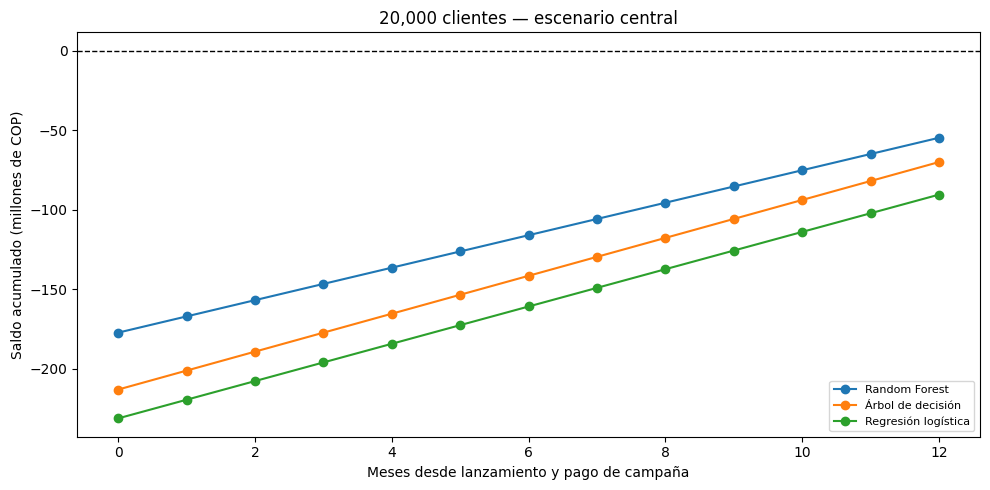

In [38]:
precision_rf_valor = p_vp_rf / p_contacto_rf
precision_equilibrio_variable = C_TOTAL_CONTACTO / (R_RETENCION * V_CLIENTE)
g_rf_valor = float(rf_economia["Ganancia por evaluación antes de fijos COP"])
n_minimo_anual = (I_IMPLEMENTACION + 12 * O_MENSUAL) / g_rf_valor if g_rf_valor > 0 else np.inf
filas_equilibrio = []
for cantidad, fila in resumen_rf_valor.iterrows():
    retencion_minima = (cantidad * p_contacto_rf * C_TOTAL_CONTACTO + I_IMPLEMENTACION + 12 * O_MENSUAL) / (cantidad * p_vp_rf * V_CLIENTE)
    filas_equilibrio.append({
        "Clientes evaluados": cantidad,
        "Precisión observada RF": precision_rf_valor,
        "Precisión mínima sin costos fijos": precision_equilibrio_variable,
        "Retención mínima para recuperar todo en 12 meses": retencion_minima,
        "Cartera mínima para recuperar todo en 12 meses": n_minimo_anual,
        "Meses de equilibrio desde lanzamiento": fila["Equilibrio desde lanzamiento (meses)"],
        "Meses de equilibrio desde inicio del desarrollo": fila["Equilibrio desde lanzamiento (meses)"] + MESES_DESARROLLO,
        "Mes de equilibrio desde inicio (cierre de mes)": fila["Equilibrio al cierre del mes"] + MESES_DESARROLLO,
        "ROI primer año sobre inversión del modelo": fila["ROI sobre inversión del modelo"],
        "Resultado neto / desembolsos totales del año": fila["Ganancia neta primer año COP"] / (I_IMPLEMENTACION + fila["Costo campaña COP"] + 12 * O_MENSUAL),
    })
resumen_equilibrio_carteras = pd.DataFrame(filas_equilibrio).set_index("Clientes evaluados")
r_minimo_anual = float(resumen_equilibrio_carteras.loc[N_CARTERA_VALOR, "Retención mínima para recuperar todo en 12 meses"])
resumen_equilibrio = resumen_equilibrio_carteras.loc[[N_CARTERA_VALOR]].copy()
display(resumen_equilibrio_carteras.T.round(4))
display(tabla_economia_carteras.loc[(slice(None), list(metricas_valor.index)), [
    "Desembolso inicial COP", "Equilibrio desde lanzamiento (meses)",
    "Equilibrio al cierre del mes", "ROI sobre inversión del modelo"]].round(2))
print("NaN indica que no se recupera la inversión dentro de los 12 meses modelados; no se extrapolan beneficios posteriores.")

meses_valor = np.arange(13)
fig, axes = plt.subplots(1, len(CARTERAS_VALOR), figsize=(10, 5), sharey=True)
for ax, cantidad in zip(np.atleast_1d(axes), CARTERAS_VALOR):
    for nombre in metricas_valor.index:
        fila = tabla_economia_carteras.loc[(cantidad, nombre)]
        saldo = -fila["Desembolso inicial COP"] + meses_valor * fila["Flujo mensual después de campaña COP"]
        ax.plot(meses_valor, saldo / 1e6, marker="o", label=nombre)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="Meses desde lanzamiento y pago de campaña", ylabel="Saldo acumulado (millones de COP)",
           title=f"{cantidad:,} clientes — escenario central")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Interpretación:** la precisión mínima de los contactos antes de costos fijos sigue siendo **26,9 %**, frente al **63,8 %** observado.

Para **20.000 clientes**, se debe evitar al menos **41,21 %** de los abandonos detectados para recuperar todos los costos en un año, por encima del 30 % supuesto. El desembolso inicial de implementación y campaña es de **COP 177,31 millones**. Con los parámetros centrales, **no hay punto de equilibrio dentro de los 12 meses de operación** y el ROI sobre implementación es **-47,42 %**. La relación entre el resultado neto y todos los desembolsos del año es **-27,20 %**. El ROI sobre implementación utiliza como denominador COP 115,5 millones; la segunda relación incluye todos los desembolsos del año.

El tamaño mínimo para recuperar implementación y operación en un año sigue siendo aproximadamente **32.927 clientes**, con las mismas tasas predictivas y supuestos económicos. La cartera exigida de 20.000 está por debajo de ese mínimo.


### 5.5. Sensibilidad de los supuestos e incertidumbre

Para la cartera de 20.000 clientes se presentan los escenarios conservador, central y favorable, variando la efectividad de retención, el valor recuperable y el costo total del contacto. Se conservan los parámetros económicos definidos para cada escenario. Estas combinaciones muestran el efecto de cambiar los supuestos; no son pronósticos de mercado ni intervalos estadísticos.


Escenarios de 20,000 clientes


,Retención,Valor cliente COP,Costo total contacto COP,Contactos esperados,Retenciones adicionales esperadas,Valor recuperado anual COP,Costo campaña COP,Beneficio campaña antes de fijos COP,Ganancia neta primer año COP,Equilibrio desde lanzamiento (meses),Equilibrio al cierre del mes
Escenario,,,,,,,,,,,
Conservador,0.10,100000.00,25000.00,3920.0,250.0,2.500000e+07,98000000.00,-7.300000e+07,-2.125000e+08,NaN,NaN
Central,0.30,195398.77,15768.94,3920.0,750.0,1.465491e+08,61814243.42,8.473484e+07,-5.476516e+07,NaN,NaN
Favorable,0.45,300000.00,12000.00,3920.0,1125.0,3.375000e+08,47040000.00,2.904600e+08,1.509600e+08,6.22,7.0


NaN en equilibrio significa que no se recupera dentro de los 12 meses modelados.


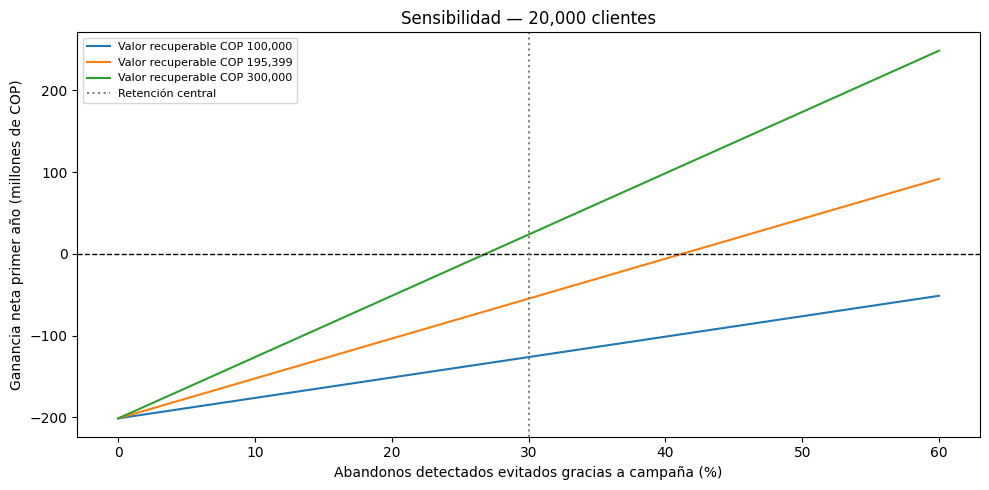

In [39]:
escenarios_valor = [
    ("Conservador", 0.10, 100_000, 25_000),
    ("Central", R_RETENCION, V_CLIENTE, C_TOTAL_CONTACTO),
    ("Favorable", 0.45, 300_000, 12_000),
]
filas_escenarios = []
for cantidad in CARTERAS_VALOR:
    for nombre, r, v, c in escenarios_valor:
        resultado = economia_campana(p_vp_rf, p_contacto_rf, n=cantidad, r=r, v=v, c=c)
        filas_escenarios.append({"Clientes evaluados": cantidad, "Escenario": nombre,
            "Retención": r, "Valor cliente COP": v, "Costo total contacto COP": c, **resultado})
tabla_escenarios_valor = pd.DataFrame(filas_escenarios).set_index(["Clientes evaluados", "Escenario"])
columnas_escenarios = ["Retención", "Valor cliente COP", "Costo total contacto COP",
    "Contactos esperados", "Retenciones adicionales esperadas", "Valor recuperado anual COP",
    "Costo campaña COP", "Beneficio campaña antes de fijos COP", "Ganancia neta primer año COP",
    "Equilibrio desde lanzamiento (meses)", "Equilibrio al cierre del mes"]
for cantidad in CARTERAS_VALOR:
    print(f"Escenarios de {cantidad:,} clientes")
    display(tabla_escenarios_valor.loc[cantidad, columnas_escenarios].round(2))

print("NaN en equilibrio significa que no se recupera dentro de los 12 meses modelados.")

rejilla_r_valor = np.linspace(0, 0.60, 61)
fig, axes = plt.subplots(1, len(CARTERAS_VALOR), figsize=(10, 5), sharey=True)
for ax, cantidad in zip(np.atleast_1d(axes), CARTERAS_VALOR):
    for v in [100_000, V_CLIENTE, 300_000]:
        beneficios = [economia_campana(p_vp_rf, p_contacto_rf, n=cantidad, r=r, v=v)["Ganancia neta primer año COP"] / 1e6
                      for r in rejilla_r_valor]
        ax.plot(100 * rejilla_r_valor, beneficios, label=f"Valor recuperable COP {v:,.0f}")
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(100 * R_RETENCION, color="grey", linestyle=":", label="Retención central")
    ax.set(xlabel="Abandonos detectados evitados gracias a campaña (%)",
           ylabel="Ganancia neta primer año (millones de COP)", title=f"Sensibilidad — {cantidad:,} clientes")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [40]:
# Bootstrap de los conteos de prueba para la cartera de 20.000 clientes.
# No requiere nuevas predicciones ni reentrenamiento.
conteos_valor = metricas_valor.loc["Random Forest", ["VP", "FP", "FN", "VN"]].to_numpy(dtype=int)
assert conteos_valor.sum() == int(n_prueba_valor)
rng_valor = np.random.default_rng(42)
conteos_boot_valor = rng_valor.multinomial(int(n_prueba_valor), conteos_valor / n_prueba_valor, size=1000)
replicas_ganancia_carteras = {}
filas_ic_valor = []
for cantidad in CARTERAS_VALOR:
    replicas = [economia_campana(vp / n_prueba_valor, (vp + fp) / n_prueba_valor, n=cantidad)["Ganancia neta primer año COP"]
                for vp, fp, fn, vn in conteos_boot_valor]
    replicas_ganancia_carteras[cantidad] = np.asarray(replicas)
    inferior, superior = np.percentile(replicas, [2.5, 97.5])
    filas_ic_valor.append({"Clientes evaluados": cantidad,
        "Ganancia neta central COP": resumen_rf_valor.loc[cantidad, "Ganancia neta primer año COP"],
        "IC bootstrap 95 % inferior COP": inferior, "IC bootstrap 95 % superior COP": superior})
tabla_ic_valor = pd.DataFrame(filas_ic_valor).set_index("Clientes evaluados")
replicas_ganancia_valor = replicas_ganancia_carteras[N_CARTERA_VALOR]
li_valor, ls_valor = tabla_ic_valor.loc[N_CARTERA_VALOR, ["IC bootstrap 95 % inferior COP", "IC bootstrap 95 % superior COP"]]
display(tabla_ic_valor.round(2))


,Ganancia neta central COP,IC bootstrap 95 % inferior COP,IC bootstrap 95 % superior COP
Clientes evaluados,,,
20000,-54765163.66,-68409932.35,-41236886.78


**Lectura de la sensibilidad:** con 10 % de efectividad, un valor recuperable de COP 100.000 y un costo total de COP 25.000 por contacto, el escenario conservador pierde **COP 212,5 millones**. El central pierde **COP 54,77 millones**. Solo el favorable presenta una ganancia neta de **COP 150,96 millones** y recupera la inversión a los **6,22 meses**, al cierre del **mes 7 de operación**. El escenario favorable exige mejorar conjuntamente la efectividad, el valor recuperable y el costo del contacto; no demuestra que esas condiciones sean alcanzables.

Con los parámetros centrales fijos, el intervalo bootstrap del 95 % del resultado neto anual está entre **−COP 68,41 y −COP 41,24 millones**: todo el intervalo corresponde a pérdidas. Este intervalo refleja solo la variación al remuestrear clientes de prueba; no incorpora la incertidumbre de la efectividad, los costos o el valor del cliente.

### 5.6. Conclusiones y limitaciones

- **Valor esperado:** con los supuestos centrales, la inversión no se recupera en el primer año. La rentabilidad depende de lograr condiciones más favorables, como las examinadas en la sensibilidad. Los resultados son estimaciones, no ganancias observadas.
- **Calidad predictiva y valor:** el modelo con mayor recall no necesariamente genera más dinero. También importa cuántos contactos innecesarios produce y cuánto cuesta cada uno.
- **Efecto de la campaña:** el dataset contiene abandono, pero no un experimento de retención. No permite estimar directamente cuántos clientes se quedarían por recibir una oferta. Se necesita un piloto con grupo de comparación para medir ese efecto adicional y comprobar el supuesto del 30 %.
- **Valor del cliente y banco promedio:** la referencia de una entidad grande mezcla segmentos y negocios. Dividir utilidades entre clientes no identifica el margen marginal de un cliente en riesgo. El descuento del 50 % no elimina esa limitación y Bancolombia no representa necesariamente al banco promedio del sector.
- **Datos y construcción:** los clientes del dataset son europeos y no se conoce su ventana temporal real. Se asumió una etiqueta anual para el ejercicio. El sobreajuste del Forest (F1 de 0,9360 en entrenamiento frente a 0,5961 en validación), la limpieza, la imputación y la falta de identificación única limitan la confianza en extrapolar el desempeño.
- **Tiempo, costos y escala:** si los contactos o los ingresos se retrasan respecto al calendario supuesto en 5.1, la recuperación también puede demorarse. El presupuesto supone sistemas y equipo base existentes; una integración más compleja, nuevos controles o mayor capacidad pueden elevarlo. No se modelan inflación futura, descuento financiero ni efectos fiscales adicionales del proyecto.
- **Uso responsable de la estimación:** antes de implementar se deben validar datos locales, efectividad de la oferta, costos reales, capacidad de atención y margen por segmento.
